In [ ]:

# EventBot - Asistente Inteligente para Salón de Eventos Sociales

# Materia: Desarrollo de Aplicaciones con Inteligencia Artificial

#Proyecto: EventBot

#Tecnologías: Python 3.10+, NLTK y Google Colab

## Objetivo
Desarrollar un chatbot basado en reglas que permita a los clientes de un salón de eventos sociales consultar:

- Disponibilidad de fechas
- Costos y paquetes
- Promociones
- Amenidades
- Capacidad del salón
- Horarios
- Ubicación
- Información para reservaciones

## Arquitectura

El proyecto utilizará programación orientada a objetos y una arquitectura modular, separando la base de conocimiento, el procesamiento de texto, la detección de intenciones y la gestión de conversaciones.



## Arquitectura conceptual de EventBot

EventBot utiliza una arquitectura modular basada en
programación orientada a objetos.

El sistema se organiza en seis componentes principales:

### 1. ConfiguracionEventBot
Centraliza parámetros generales y rutas de archivos.

### 2. BaseConocimiento
Administra la información del salón, los paquetes,
la disponibilidad y las promociones mediante JSON.

### 3. ProcesadorTexto
Normaliza el texto, elimina acentos y realiza
tokenización utilizando NLTK.

### 4. DetectorIntenciones
Identifica la intención principal de la consulta
mediante reglas y extrae entidades como paquetes,
fechas y cantidades de invitados.

### 5. GestorConversacion
Construye respuestas en lenguaje natural utilizando
las intenciones y los datos disponibles.

### 6. EventBot
Integra los módulos, administra las sesiones
y almacena el historial de las interacciones.

## Flujo de funcionamiento

1. El cliente escribe una consulta.
2. EventBot recibe el mensaje.
3. DetectorIntenciones utiliza ProcesadorTexto.
4. Se identifica la intención y sus entidades.
5. GestorConversacion consulta BaseConocimiento.
6. Se genera una respuesta basada en reglas.
7. EventBot muestra y registra la respuesta.

## Ventajas de la arquitectura

- Separación de responsabilidades.
- Facilidad de mantenimiento.
- Reutilización de componentes.
- Posibilidad de ampliar las reglas.
- Integración futura de modelos de IA.
- Pruebas independientes de los módulos.


In [2]:
import sys

print("Proyecto: EventBot")
print("Versión de Python:", sys.version)

Proyecto: EventBot
Versión de Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [3]:
# Instalación de la biblioteca NLTK

%pip install -q nltk

In [4]:
# Importación de bibliotecas

import os
import json
import re
import unicodedata
from pathlib import Path

import nltk
from nltk.tokenize import wordpunct_tokenize

print("Bibliotecas importadas correctamente.")
print("Versión de NLTK:", nltk.__version__)


Bibliotecas importadas correctamente.
Versión de NLTK: 3.9.1


In [5]:
# ==========================================
# EVENTBOT - CREACIÓN DE CARPETAS
# ==========================================

from pathlib import Path

# Carpeta principal del proyecto
RUTA_PROYECTO = Path("/content/EventBot")

# Carpetas del proyecto
CARPETAS = [
    "src",
    "data",
    "notebooks",
    "tests",
    "evidencias",
    "resultados"
]

# Crear carpeta principal
RUTA_PROYECTO.mkdir(parents=True, exist_ok=True)

# Crear subcarpetas
for carpeta in CARPETAS:
    ruta = RUTA_PROYECTO / carpeta
    ruta.mkdir(parents=True, exist_ok=True)
    print(f"Carpeta creada: {ruta}")

print("\nEstructura de EventBot creada correctamente.")


Carpeta creada: /content/EventBot/src
Carpeta creada: /content/EventBot/data
Carpeta creada: /content/EventBot/notebooks
Carpeta creada: /content/EventBot/tests
Carpeta creada: /content/EventBot/evidencias
Carpeta creada: /content/EventBot/resultados

Estructura de EventBot creada correctamente.


In [6]:
# Mostrar estructura del proyecto

print("ESTRUCTURA DEL PROYECTO EVENTBOT")
print("=" * 40)

for ruta in sorted(RUTA_PROYECTO.rglob("*")):
    nivel = len(ruta.relative_to(RUTA_PROYECTO).parts)
    print("    " * (nivel - 1) + "|-- " + ruta.name)


ESTRUCTURA DEL PROYECTO EVENTBOT
|-- data
|-- evidencias
|-- notebooks
|-- resultados
|-- src
|-- tests


In [7]:
# ==========================================
# EVENTBOT - CREACIÓN DE MÓDULOS PYTHON
# ==========================================

archivos_python = [
    "configuracion.py",
    "base_conocimiento.py",
    "procesador_texto.py",
    "detector_intenciones.py",
    "gestor_conversacion.py",
    "eventbot.py"
]

ruta_src = RUTA_PROYECTO / "src"

for archivo in archivos_python:
    ruta_archivo = ruta_src / archivo

    # Crear únicamente si todavía no existe
    if not ruta_archivo.exists():
        ruta_archivo.write_text(
            f'"""Módulo {archivo} del proyecto EventBot."""\n',
            encoding="utf-8"
        )
        print(f"Archivo creado: {archivo}")
    else:
        print(f"El archivo ya existe: {archivo}")

# Permitir importar src como paquete de Python
(ruta_src / "__init__.py").touch(exist_ok=True)

print("\nMódulos Python creados correctamente.")


Archivo creado: configuracion.py
Archivo creado: base_conocimiento.py
Archivo creado: procesador_texto.py
Archivo creado: detector_intenciones.py
Archivo creado: gestor_conversacion.py
Archivo creado: eventbot.py

Módulos Python creados correctamente.


In [8]:
# ==========================================
# EVENTBOT - BASE DE CONOCIMIENTO
# ==========================================

archivos_json = [
    "informacion_salon.json",
    "paquetes.json",
    "disponibilidad.json",
    "promociones.json"
]

ruta_data = RUTA_PROYECTO / "data"

for archivo in archivos_json:
    ruta_archivo = ruta_data / archivo

    if not ruta_archivo.exists():
        with open(ruta_archivo, "w", encoding="utf-8") as f:
            json.dump({}, f, ensure_ascii=False, indent=4)

        print(f"Archivo JSON creado: {archivo}")
    else:
        print(f"El archivo ya existe: {archivo}")

print("\nArchivos de base de conocimiento creados.")


Archivo JSON creado: informacion_salon.json
Archivo JSON creado: paquetes.json
Archivo JSON creado: disponibilidad.json
Archivo JSON creado: promociones.json

Archivos de base de conocimiento creados.


In [9]:
# Verificar estructura final

print("\nPROYECTO EVENTBOT")
print("=" * 50)

for ruta in sorted(RUTA_PROYECTO.rglob("*")):
    nivel = len(ruta.relative_to(RUTA_PROYECTO).parts)
    sangria = "    " * (nivel - 1)

    if ruta.is_dir():
        print(f"{sangria}[CARPETA] {ruta.name}")
    else:
        print(f"{sangria}[ARCHIVO] {ruta.name}")



PROYECTO EVENTBOT
[CARPETA] data
    [ARCHIVO] disponibilidad.json
    [ARCHIVO] informacion_salon.json
    [ARCHIVO] paquetes.json
    [ARCHIVO] promociones.json
[CARPETA] evidencias
[CARPETA] notebooks
[CARPETA] resultados
[CARPETA] src
    [ARCHIVO] __init__.py
    [ARCHIVO] base_conocimiento.py
    [ARCHIVO] configuracion.py
    [ARCHIVO] detector_intenciones.py
    [ARCHIVO] eventbot.py
    [ARCHIVO] gestor_conversacion.py
    [ARCHIVO] procesador_texto.py
[CARPETA] tests


In [11]:

# ============================================
# EVENTBOT - CONFIGURACIÓN DE RUTAS
# ============================================

from pathlib import Path
import json

RUTA_PROYECTO = Path("/content/EventBot")
RUTA_DATA = RUTA_PROYECTO / "data"

# Verificar que existe la carpeta
RUTA_DATA.mkdir(parents=True, exist_ok=True)

print("Proyecto:", RUTA_PROYECTO)
print("Base de conocimiento:", RUTA_DATA)


Proyecto: /content/EventBot
Base de conocimiento: /content/EventBot/data


In [12]:
# ============================================
# INFORMACIÓN GENERAL - SALÓN DESTELLOS
# ============================================

informacion_salon = {
    "nombre": "Salón Destellos",
    "asistente": "EventBot",
    "descripcion": (
        "Salón de eventos sociales especializado en bodas, "
        "XV años, cumpleaños, bautizos, graduaciones y aniversarios."
    ),
    "capacidad_minima": 50,
    "capacidad_maxima": 300,
    "horario_atencion": "Lunes a sábado de 10:00 a 19:00",
    "duracion_evento_horas": 5,
    "ubicacion": "Monterrey, Nuevo León, México (ubicación simulada)",
    "telefono": "No disponible en esta versión de demostración",
    "correo": "No disponible en esta versión de demostración",
    "estacionamiento": True,
    "amenidades": [
        "Mesas y sillas",
        "Mantelería",
        "Aire acondicionado",
        "Iluminación ambiental",
        "Equipo de sonido",
        "Pista de baile",
        "Área para fotografías",
        "Baños",
        "Estacionamiento"
    ],
    "tipos_eventos": [
        "Bodas",
        "XV años",
        "Cumpleaños",
        "Bautizos",
        "Graduaciones",
        "Aniversarios"
    ],
    "procedimiento_reservacion": (
        "El cliente debe consultar la disponibilidad de la fecha "
        "y posteriormente contactar a un asesor para confirmar "
        "la cotización y realizar la reservación."
    )
}

ruta_archivo = RUTA_DATA / "informacion_salon.json"

with open(ruta_archivo, "w", encoding="utf-8") as archivo:
    json.dump(
        informacion_salon,
        archivo,
        ensure_ascii=False,
        indent=4
    )

print("Información del Salón Destellos guardada correctamente.")


Información del Salón Destellos guardada correctamente.


In [13]:

# ============================================
# INFORMACIÓN GENERAL - SALÓN DESTELLOS
# ============================================

informacion_salon = {
    "nombre": "Salón Destellos",
    "asistente": "EventBot",
    "descripcion": (
        "Salón de eventos sociales especializado en bodas, "
        "XV años, cumpleaños, bautizos, graduaciones y aniversarios."
    ),
    "capacidad_minima": 50,
    "capacidad_maxima": 300,
    "horario_atencion": "Lunes a sábado de 10:00 a 19:00",
    "duracion_evento_horas": 5,
    "ubicacion": "Monterrey, Nuevo León, México (ubicación simulada)",
    "telefono": "No disponible en esta versión de demostración",
    "correo": "No disponible en esta versión de demostración",
    "estacionamiento": True,
    "amenidades": [
        "Mesas y sillas",
        "Mantelería",
        "Aire acondicionado",
        "Iluminación ambiental",
        "Equipo de sonido",
        "Pista de baile",
        "Área para fotografías",
        "Baños",
        "Estacionamiento"
    ],
    "tipos_eventos": [
        "Bodas",
        "XV años",
        "Cumpleaños",
        "Bautizos",
        "Graduaciones",
        "Aniversarios"
    ],
    "procedimiento_reservacion": (
        "El cliente debe consultar la disponibilidad de la fecha "
        "y posteriormente contactar a un asesor para confirmar "
        "la cotización y realizar la reservación."
    )
}

ruta_archivo = RUTA_DATA / "informacion_salon.json"

with open(ruta_archivo, "w", encoding="utf-8") as archivo:
    json.dump(
        informacion_salon,
        archivo,
        ensure_ascii=False,
        indent=4
    )

print("Información del Salón Destellos guardada correctamente.")


Información del Salón Destellos guardada correctamente.


In [14]:

# ============================================
# PAQUETES Y PRECIOS - SALÓN DESTELLOS
# ============================================

paquetes = [
    {
        "id": "PKG001",
        "nombre": "Esencial",
        "precio": 18000,
        "moneda": "MXN",
        "capacidad_maxima": 50,
        "duracion_horas": 5,
        "servicios": [
            "Renta del salón",
            "Mesas y sillas",
            "Mantelería",
            "Aire acondicionado"
        ]
    },
    {
        "id": "PKG002",
        "nombre": "Clásico",
        "precio": 32000,
        "moneda": "MXN",
        "capacidad_maxima": 100,
        "duracion_horas": 5,
        "servicios": [
            "Renta del salón",
            "Mesas y sillas",
            "Mantelería",
            "Aire acondicionado",
            "Equipo de sonido",
            "Iluminación ambiental"
        ]
    },
    {
        "id": "PKG003",
        "nombre": "Premium",
        "precio": 48000,
        "moneda": "MXN",
        "capacidad_maxima": 150,
        "duracion_horas": 5,
        "servicios": [
            "Renta del salón",
            "Mesas y sillas",
            "Mantelería",
            "Aire acondicionado",
            "Equipo de sonido",
            "Iluminación ambiental",
            "Pista de baile",
            "Decoración básica"
        ]
    },
    {
        "id": "PKG004",
        "nombre": "Diamante",
        "precio": 75000,
        "moneda": "MXN",
        "capacidad_maxima": 300,
        "duracion_horas": 5,
        "servicios": [
            "Renta del salón",
            "Mesas y sillas",
            "Mantelería",
            "Aire acondicionado",
            "Equipo de sonido",
            "Iluminación ambiental",
            "Pista de baile",
            "Decoración especial",
            "Servicio de meseros"
        ]
    }
]

with open(RUTA_DATA / "paquetes.json", "w", encoding="utf-8") as archivo:
    json.dump(paquetes, archivo, ensure_ascii=False, indent=4)

print("Paquetes y precios guardados correctamente.")


Paquetes y precios guardados correctamente.


In [15]:

# ============================================
# DISPONIBILIDAD - SALÓN DESTELLOS
# ============================================

disponibilidad = {
    "2026-11-07": "disponible",
    "2026-11-14": "ocupada",
    "2026-11-15": "disponible",
    "2026-11-21": "disponible",
    "2026-11-28": "ocupada",
    "2026-12-05": "disponible",
    "2026-12-12": "ocupada",
    "2026-12-19": "disponible",
    "2026-12-20": "disponible",
    "2026-12-26": "ocupada",
    "2027-01-09": "disponible",
    "2027-01-16": "ocupada",
    "2027-01-23": "disponible"
}

with open(RUTA_DATA / "disponibilidad.json", "w", encoding="utf-8") as archivo:
    json.dump(disponibilidad, archivo, ensure_ascii=False, indent=4)

print("Calendario de disponibilidad guardado correctamente.")


Calendario de disponibilidad guardado correctamente.


In [16]:

# ============================================
# PROMOCIONES - SALÓN DESTELLOS
# ============================================

promociones = [
    {
        "id": "PROMO001",
        "nombre": "Descuento entre semana",
        "descripcion": "10% de descuento en eventos de lunes a jueves.",
        "descuento_porcentaje": 10,
        "fecha_inicio": "2026-10-01",
        "fecha_fin": "2027-03-31",
        "dias_aplicables": [
            "lunes", "martes", "miercoles", "jueves"
        ],
        "aplica_paquetes": [
            "Esencial", "Clásico", "Premium", "Diamante"
        ]
    },
    {
        "id": "PROMO002",
        "nombre": "Promoción XV años",
        "descripcion": "5% de descuento en el paquete Premium para XV años.",
        "descuento_porcentaje": 5,
        "fecha_inicio": "2026-10-01",
        "fecha_fin": "2026-12-31",
        "dias_aplicables": [
            "lunes", "martes", "miercoles",
            "jueves", "viernes", "sabado", "domingo"
        ],
        "aplica_paquetes": ["Premium"],
        "tipo_evento": "XV años"
    }
]

with open(RUTA_DATA / "promociones.json", "w", encoding="utf-8") as archivo:
    json.dump(promociones, archivo, ensure_ascii=False, indent=4)

print("Promociones guardadas correctamente.")


Promociones guardadas correctamente.


In [17]:

# ============================================
# VALIDACIÓN DE LA BASE DE CONOCIMIENTO
# ============================================

archivos = [
    "informacion_salon.json",
    "paquetes.json",
    "disponibilidad.json",
    "promociones.json"
]

for nombre_archivo in archivos:
    ruta = RUTA_DATA / nombre_archivo

    try:
        with open(ruta, "r", encoding="utf-8") as archivo:
            datos = json.load(archivo)

        print(f"OK - {nombre_archivo}")

        if isinstance(datos, list):
            print(f"   Registros: {len(datos)}")
        elif isinstance(datos, dict):
            print(f"   Elementos: {len(datos)}")

    except Exception as error:
        print(f"ERROR - {nombre_archivo}: {error}")

print("\nValidación finalizada.")


OK - informacion_salon.json
   Elementos: 14
OK - paquetes.json
   Registros: 4
OK - disponibilidad.json
   Elementos: 13
OK - promociones.json
   Registros: 2

Validación finalizada.


In [18]:

# ============================================
# PRIMERA CONSULTA DE INFORMACIÓN
# ============================================

with open(RUTA_DATA / "informacion_salon.json",
          "r", encoding="utf-8") as archivo:
    salon = json.load(archivo)

with open(RUTA_DATA / "paquetes.json",
          "r", encoding="utf-8") as archivo:
    lista_paquetes = json.load(archivo)

print("Bienvenido a", salon["nombre"])
print("Capacidad máxima:", salon["capacidad_maxima"], "personas")

print("\nPAQUETES DISPONIBLES")
print("-" * 40)

for paquete in lista_paquetes:
    print(
        f"{paquete['nombre']}: "
        f"${paquete['precio']:,.2f} MXN "
        f"- Hasta {paquete['capacidad_maxima']} invitados"
    )


Bienvenido a Salón Destellos
Capacidad máxima: 300 personas

PAQUETES DISPONIBLES
----------------------------------------
Esencial: $18,000.00 MXN - Hasta 50 invitados
Clásico: $32,000.00 MXN - Hasta 100 invitados
Premium: $48,000.00 MXN - Hasta 150 invitados
Diamante: $75,000.00 MXN - Hasta 300 invitados


In [19]:

%%writefile /content/EventBot/src/base_conocimiento.py

# ============================================
# EVENTBOT - BASE DE CONOCIMIENTO
# Salón Destellos
# ============================================

import json
from pathlib import Path
from datetime import date


class BaseConocimiento:
    """
    Administra la información del Salón Destellos
    almacenada en archivos JSON.
    """

    def __init__(self, ruta_data):

        self.ruta_data = Path(ruta_data)

        self.informacion_salon = self._cargar_json(
            "informacion_salon.json"
        )

        self.paquetes = self._cargar_json(
            "paquetes.json"
        )

        self.disponibilidad = self._cargar_json(
            "disponibilidad.json"
        )

        self.promociones = self._cargar_json(
            "promociones.json"
        )

    # ----------------------------------------
    # CARGA DE ARCHIVOS
    # ----------------------------------------

    def _cargar_json(self, nombre_archivo):
        """Carga un archivo JSON y devuelve sus datos."""

        ruta = self.ruta_data / nombre_archivo

        if not ruta.exists():
            raise FileNotFoundError(
                f"No se encontró el archivo: {ruta}"
            )

        with open(ruta, "r", encoding="utf-8") as archivo:
            return json.load(archivo)

    # ----------------------------------------
    # INFORMACIÓN GENERAL
    # ----------------------------------------

    def obtener_informacion_salon(self):
        """Devuelve la información general del salón."""

        return self.informacion_salon.copy()

    def obtener_capacidad(self):
        """Devuelve la capacidad máxima del salón."""

        return self.informacion_salon["capacidad_maxima"]

    def obtener_amenidades(self):
        """Devuelve las amenidades disponibles."""

        return self.informacion_salon["amenidades"].copy()

    def obtener_tipos_eventos(self):
        """Devuelve los tipos de eventos que se atienden."""

        return self.informacion_salon["tipos_eventos"].copy()

    # ----------------------------------------
    # PAQUETES Y PRECIOS
    # ----------------------------------------

    def obtener_paquetes(self):
        """Devuelve todos los paquetes disponibles."""

        return [p.copy() for p in self.paquetes]

    def buscar_paquete(self, nombre):
        """Busca un paquete por su nombre."""

        nombre = nombre.strip().casefold()

        for paquete in self.paquetes:

            if paquete["nombre"].casefold() == nombre:
                return paquete.copy()

        return None

    def recomendar_paquete(self, invitados):
        """
        Recomienda el paquete de menor capacidad
        que pueda atender al número de invitados.
        """

        if not isinstance(invitados, int) or isinstance(invitados, bool):
            raise ValueError(
                "El número de invitados debe ser un entero."
            )

        if invitados < self.informacion_salon["capacidad_minima"]:
            return None

        opciones = [
            paquete
            for paquete in self.paquetes
            if paquete["capacidad_maxima"] >= invitados
        ]

        if not opciones:
            return None

        opciones.sort(
            key=lambda p: (p["capacidad_maxima"], p["precio"])
        )

        return opciones[0].copy()

    # ----------------------------------------
    # DISPONIBILIDAD DE FECHAS
    # ----------------------------------------

    def consultar_disponibilidad(self, fecha):
        """
        Consulta una fecha en formato YYYY-MM-DD.

        Posibles resultados:
        disponible, ocupada, no_registrada,
        fecha_pasada o fecha_invalida.
        """

        try:
            fecha_consulta = date.fromisoformat(fecha)
        except (ValueError, TypeError):
            return "fecha_invalida"

        if fecha_consulta < date.today():
            return "fecha_pasada"

        return self.disponibilidad.get(
            fecha,
            "no_registrada"
        )

    def obtener_fechas_disponibles(self):
        """Devuelve fechas futuras registradas como disponibles."""

        hoy = date.today()

        fechas = [
            fecha
            for fecha, estado in self.disponibilidad.items()
            if estado == "disponible"
            and date.fromisoformat(fecha) >= hoy
        ]

        return sorted(fechas)

    # ----------------------------------------
    # PROMOCIONES
    # ----------------------------------------

    def obtener_promociones(self, fecha_consulta=None):
        """
        Devuelve promociones vigentes en una fecha.

        Si no se proporciona una fecha,
        utiliza la fecha actual.
        """

        if fecha_consulta is None:
            fecha_consulta = date.today()

        elif isinstance(fecha_consulta, str):
            fecha_consulta = date.fromisoformat(fecha_consulta)

        promociones_vigentes = []

        for promocion in self.promociones:

            inicio = date.fromisoformat(
                promocion["fecha_inicio"]
            )

            fin = date.fromisoformat(
                promocion["fecha_fin"]
            )

            if inicio <= fecha_consulta <= fin:
                promociones_vigentes.append(
                    promocion.copy()
                )

        return promociones_vigentes


Overwriting /content/EventBot/src/base_conocimiento.py


In [20]:

# ============================================
# IMPORTAR BASE DE CONOCIMIENTO
# ============================================

import sys

RUTA_PROYECTO = "/content/EventBot"

if RUTA_PROYECTO not in sys.path:
    sys.path.insert(0, RUTA_PROYECTO)

from src.base_conocimiento import BaseConocimiento

base = BaseConocimiento(
    "/content/EventBot/data"
)

print("Base de conocimiento cargada correctamente.")


Base de conocimiento cargada correctamente.


In [21]:

# ============================================
# PRUEBA 1 - INFORMACIÓN GENERAL
# ============================================

informacion = base.obtener_informacion_salon()

print("Nombre:", informacion["nombre"])
print("Descripción:", informacion["descripcion"])
print("Capacidad máxima:", base.obtener_capacidad())

print("\nAmenidades:")

for amenidad in base.obtener_amenidades():
    print("-", amenidad)


Nombre: Salón Destellos
Descripción: Salón de eventos sociales especializado en bodas, XV años, cumpleaños, bautizos, graduaciones y aniversarios.
Capacidad máxima: 300

Amenidades:
- Mesas y sillas
- Mantelería
- Aire acondicionado
- Iluminación ambiental
- Equipo de sonido
- Pista de baile
- Área para fotografías
- Baños
- Estacionamiento


In [22]:

# ============================================
# PRUEBA 2 - CONSULTAR PAQUETES
# ============================================

paquetes = base.obtener_paquetes()

print("PAQUETES - SALÓN DESTELLOS")
print("=" * 45)

for paquete in paquetes:

    print("\nPaquete:", paquete["nombre"])
    print("Precio: $", f"{paquete['precio']:,.2f}", "MXN")
    print("Capacidad:", paquete["capacidad_maxima"])
    print("Duración:", paquete["duracion_horas"], "horas")


PAQUETES - SALÓN DESTELLOS

Paquete: Esencial
Precio: $ 18,000.00 MXN
Capacidad: 50
Duración: 5 horas

Paquete: Clásico
Precio: $ 32,000.00 MXN
Capacidad: 100
Duración: 5 horas

Paquete: Premium
Precio: $ 48,000.00 MXN
Capacidad: 150
Duración: 5 horas

Paquete: Diamante
Precio: $ 75,000.00 MXN
Capacidad: 300
Duración: 5 horas


In [23]:

# ============================================
# PRUEBA 3 - RECOMENDACIÓN DE PAQUETE
# ============================================

numero_invitados = 120

paquete = base.recomendar_paquete(numero_invitados)

if paquete:

    print(f"Para {numero_invitados} invitados recomendamos:")
    print("Paquete:", paquete["nombre"])
    print(f"Precio: ${paquete['precio']:,.2f} MXN")
    print("Capacidad:", paquete["capacidad_maxima"])

else:

    print(
        "No contamos con un paquete para "
        "esa cantidad de invitados."
    )


Para 120 invitados recomendamos:
Paquete: Premium
Precio: $48,000.00 MXN
Capacidad: 150


In [24]:

# ============================================
# PRUEBA 4 - DISPONIBILIDAD
# ============================================

fechas_prueba = [
    "2026-11-15",
    "2026-11-14",
    "2026-12-24",
    "fecha_incorrecta"
]

for fecha in fechas_prueba:

    estado = base.consultar_disponibilidad(fecha)

    print(f"Fecha: {fecha} -> Estado: {estado}")


Fecha: 2026-11-15 -> Estado: disponible
Fecha: 2026-11-14 -> Estado: ocupada
Fecha: 2026-12-24 -> Estado: no_registrada
Fecha: fecha_incorrecta -> Estado: fecha_invalida


In [25]:

# ============================================
# PRUEBA 5 - PROMOCIONES
# ============================================

promociones = base.obtener_promociones()

print("PROMOCIONES VIGENTES")
print("=" * 45)

if promociones:

    for promocion in promociones:

        print("\nPromoción:", promocion["nombre"])
        print("Descripción:", promocion["descripcion"])
        print("Descuento:", promocion["descuento_porcentaje"], "%")

else:

    print("No hay promociones vigentes.")


PROMOCIONES VIGENTES

Promoción: Descuento entre semana
Descripción: 10% de descuento en eventos de lunes a jueves.
Descuento: 10 %

Promoción: Promoción XV años
Descripción: 5% de descuento en el paquete Premium para XV años.
Descuento: 5 %


In [26]:

# ============================================
# VALIDACIÓN DE BASECONOCIMIENTO
# ============================================

from datetime import date

# Información general
assert base.obtener_informacion_salon()["nombre"] == "Salón Destellos"

# Capacidad
assert base.obtener_capacidad() == 300

# Paquetes
assert len(base.obtener_paquetes()) == 4

# Búsqueda por nombre
assert base.buscar_paquete("premium")["precio"] == 48000

# Recomendación
assert base.recomendar_paquete(120)["nombre"] == "Premium"

# Cantidad fuera de capacidad
assert base.recomendar_paquete(350) is None

# Fecha inválida
assert base.consultar_disponibilidad("fecha_incorrecta") == "fecha_invalida"

# Fecha no registrada, siempre futura
assert base.consultar_disponibilidad("2099-12-24") == "no_registrada"

# Promociones en fecha específica
assert len(base.obtener_promociones("2026-11-15")) == 2

print("Todas las validaciones de BaseConocimiento fueron exitosas.")


Todas las validaciones de BaseConocimiento fueron exitosas.


In [27]:

%%writefile /content/EventBot/src/procesador_texto.py

# ============================================
# EVENTBOT - PROCESADOR DE TEXTO
# Salón Destellos
# ============================================

import re
import unicodedata

from nltk.tokenize import wordpunct_tokenize


class ProcesadorTexto:
    """
    Procesa las consultas escritas por los clientes.

    Utiliza NLTK para tokenización y técnicas
    básicas de normalización de texto.
    """

    def __init__(self):

        # Palabras frecuentes que no suelen aportar
        # información para identificar una intención.
        self.stopwords = {
            "el", "la", "los", "las",
            "un", "una", "unos", "unas",
            "de", "del", "al", "en",
            "por", "para", "con",
            "me", "te", "se", "le",
            "mi", "tu", "su",
            "que", "como", "cual",
            "es", "son", "ser",
            "puedes", "podrias",
            "favor", "quiero", "quisiera"
        }

    # ----------------------------------------
    # NORMALIZAR TEXTO
    # ----------------------------------------

    def normalizar(self, texto):
        """
        Convierte a minúsculas, elimina acentos
        y normaliza espacios.
        """

        if not isinstance(texto, str):
            raise TypeError("El texto debe ser una cadena.")

        texto = texto.lower().strip()

        # Separar caracteres acentuados
        texto = unicodedata.normalize("NFD", texto)

        # Eliminar marcas de acentuación
        texto = "".join(
            caracter
            for caracter in texto
            if unicodedata.category(caracter) != "Mn"
        )

        # Eliminar signos de puntuación
        # Conservamos números para fechas y cantidades.
        texto = re.sub(r"[^a-z0-9\s]", " ", texto)

        # Eliminar espacios adicionales
        texto = re.sub(r"\s+", " ", texto).strip()

        return texto

    # ----------------------------------------
    # TOKENIZACIÓN
    # ----------------------------------------

    def tokenizar(self, texto):
        """
        Divide el texto normalizado en palabras
        utilizando NLTK.
        """

        texto_normalizado = self.normalizar(texto)

        tokens = wordpunct_tokenize(texto_normalizado)

        return tokens

    # ----------------------------------------
    # ELIMINAR PALABRAS VACÍAS
    # ----------------------------------------

    def eliminar_stopwords(self, tokens):
        """
        Elimina palabras frecuentes de una lista
        de tokens.
        """

        return [
            token
            for token in tokens
            if token not in self.stopwords
        ]

    # ----------------------------------------
    # PROCESAR CONSULTA
    # ----------------------------------------

    def procesar(self, texto):
        """
        Ejecuta el procesamiento completo
        de una consulta.
        """

        texto_normalizado = self.normalizar(texto)

        tokens = self.tokenizar(texto)

        tokens_relevantes = self.eliminar_stopwords(tokens)

        return {
            "texto_original": texto,
            "texto_normalizado": texto_normalizado,
            "tokens": tokens,
            "tokens_relevantes": tokens_relevantes
        }


Overwriting /content/EventBot/src/procesador_texto.py


In [28]:

# ============================================
# IMPORTAR PROCESADOR DE TEXTO
# ============================================

import sys

RUTA_PROYECTO = "/content/EventBot"

if RUTA_PROYECTO not in sys.path:
    sys.path.insert(0, RUTA_PROYECTO)

from src.procesador_texto import ProcesadorTexto

procesador = ProcesadorTexto()

print("ProcesadorTexto cargado correctamente.")


ProcesadorTexto cargado correctamente.


In [29]:

# ============================================
# PRUEBA 1 - NORMALIZACIÓN
# ============================================

consulta = "¿CUÁNTO CUESTA EL SALÓN???"

resultado = procesador.normalizar(consulta)

print("Consulta original:", consulta)
print("Consulta normalizada:", resultado)


Consulta original: ¿CUÁNTO CUESTA EL SALÓN???
Consulta normalizada: cuanto cuesta el salon


In [30]:

# ============================================
# PRUEBA 2 - TOKENIZACIÓN
# ============================================

consulta = "¿Tienen disponible el salón para 150 personas?"

tokens = procesador.tokenizar(consulta)

print("Consulta:", consulta)
print("Tokens:", tokens)


Consulta: ¿Tienen disponible el salón para 150 personas?
Tokens: ['tienen', 'disponible', 'el', 'salon', 'para', '150', 'personas']


In [31]:

# ============================================
# PRUEBA 3 - STOPWORDS
# ============================================

consulta = "Quisiera saber el precio del paquete Premium"

tokens = procesador.tokenizar(consulta)

tokens_relevantes = procesador.eliminar_stopwords(tokens)

print("Tokens originales:", tokens)
print("Tokens relevantes:", tokens_relevantes)


Tokens originales: ['quisiera', 'saber', 'el', 'precio', 'del', 'paquete', 'premium']
Tokens relevantes: ['saber', 'precio', 'paquete', 'premium']


In [32]:

# ============================================
# PRUEBA 4 - PROCESAMIENTO COMPLETO
# ============================================

consulta = "¡Hola! ¿Me puedes decir cuánto cuesta el salón para 150 personas?"

resultado = procesador.procesar(consulta)

print("Texto original:")
print(resultado["texto_original"])

print("\nTexto normalizado:")
print(resultado["texto_normalizado"])

print("\nTokens:")
print(resultado["tokens"])

print("\nTokens relevantes:")
print(resultado["tokens_relevantes"])


Texto original:
¡Hola! ¿Me puedes decir cuánto cuesta el salón para 150 personas?

Texto normalizado:
hola me puedes decir cuanto cuesta el salon para 150 personas

Tokens:
['hola', 'me', 'puedes', 'decir', 'cuanto', 'cuesta', 'el', 'salon', 'para', '150', 'personas']

Tokens relevantes:
['hola', 'decir', 'cuanto', 'cuesta', 'salon', '150', 'personas']


In [33]:

# ============================================
# PRUEBA 5 - CONSULTAS DIFERENTES
# ============================================

consultas = [
    "Hola, buenos días",
    "¿Cuánto cuesta rentar el salón?",
    "¿Tienen disponible el 15 de noviembre?",
    "¿Qué promociones manejan?",
    "¿Cuáles son las amenidades?",
    "¿Qué incluye el paquete Premium?",
    "¿Cuál es la capacidad máxima?",
    "¿Cómo puedo reservar una fecha?",
    "¿Dónde están ubicados?",
    "Muchas gracias, adiós"
]

for numero, consulta in enumerate(consultas, start=1):

    resultado = procesador.procesar(consulta)

    print(f"\nCONSULTA {numero}")
    print("Original:", resultado["texto_original"])
    print("Normalizada:", resultado["texto_normalizado"])
    print("Relevantes:", resultado["tokens_relevantes"])
    print("-" * 50)



CONSULTA 1
Original: Hola, buenos días
Normalizada: hola buenos dias
Relevantes: ['hola', 'buenos', 'dias']
--------------------------------------------------

CONSULTA 2
Original: ¿Cuánto cuesta rentar el salón?
Normalizada: cuanto cuesta rentar el salon
Relevantes: ['cuanto', 'cuesta', 'rentar', 'salon']
--------------------------------------------------

CONSULTA 3
Original: ¿Tienen disponible el 15 de noviembre?
Normalizada: tienen disponible el 15 de noviembre
Relevantes: ['tienen', 'disponible', '15', 'noviembre']
--------------------------------------------------

CONSULTA 4
Original: ¿Qué promociones manejan?
Normalizada: que promociones manejan
Relevantes: ['promociones', 'manejan']
--------------------------------------------------

CONSULTA 5
Original: ¿Cuáles son las amenidades?
Normalizada: cuales son las amenidades
Relevantes: ['cuales', 'amenidades']
--------------------------------------------------

CONSULTA 6
Original: ¿Qué incluye el paquete Premium?
Normalizada: qu

In [34]:

# ============================================
# VALIDACIÓN AUTOMÁTICA
# ============================================

# Normalización
assert procesador.normalizar(
    "¿CUÁNTO CUESTA?"
) == "cuanto cuesta"

# Tokenización
assert procesador.tokenizar(
    "Hola mundo"
) == ["hola", "mundo"]

# Conservación de números
assert "150" in procesador.tokenizar(
    "Evento para 150 personas"
)

# Eliminación de palabras vacías
assert procesador.eliminar_stopwords(
    ["el", "precio", "del", "salon"]
) == ["precio", "salon"]

# Procesamiento completo
resultado = procesador.procesar(
    "¿Qué promociones tienen?"
)

assert "promociones" in resultado["tokens_relevantes"]

# Manejo de entrada incorrecta
try:
    procesador.normalizar(123)
    raise AssertionError("Se esperaba TypeError")
except TypeError:
    pass

print("Todas las validaciones de ProcesadorTexto fueron exitosas.")


Todas las validaciones de ProcesadorTexto fueron exitosas.


In [35]:

from pathlib import Path

ruta_modulo = Path(
    "/content/EventBot/src/procesador_texto.py"
)

if ruta_modulo.exists():
    print("Archivo encontrado:", ruta_modulo)
    print("Tamaño:", ruta_modulo.stat().st_size, "bytes")
else:
    print("ERROR: No se encontró el módulo.")


Archivo encontrado: /content/EventBot/src/procesador_texto.py
Tamaño: 3227 bytes


In [36]:

%%writefile /content/EventBot/src/detector_intenciones.py

# ============================================
# EVENTBOT - DETECTOR DE INTENCIONES
# Salón Destellos
# ============================================

import re
from datetime import date

from src.procesador_texto import ProcesadorTexto


class DetectorIntenciones:
    """
    Detecta la intención principal del usuario
    mediante reglas y palabras clave.

    También extrae entidades:
    - Paquete
    - Número de invitados
    - Fecha
    """

    def __init__(self):

        self.procesador = ProcesadorTexto()

        self.paquetes = {
            "esencial": "Esencial",
            "clasico": "Clásico",
            "premium": "Premium",
            "diamante": "Diamante"
        }

        self.meses = {
            "enero": 1,
            "febrero": 2,
            "marzo": 3,
            "abril": 4,
            "mayo": 5,
            "junio": 6,
            "julio": 7,
            "agosto": 8,
            "septiembre": 9,
            "setiembre": 9,
            "octubre": 10,
            "noviembre": 11,
            "diciembre": 12
        }

    # ----------------------------------------
    # DETECTAR INTENCIÓN
    # ----------------------------------------

    def detectar_intencion(self, texto):

        normalizado = self.procesador.normalizar(texto)
        tokens = set(self.procesador.tokenizar(texto))

        def contiene_frase(frase):
            return (
                f" {frase} " in f" {normalizado} "
            )

        # 1. Disponibilidad
        if (
            tokens & {
                "disponible", "disponibilidad",
                "libre", "ocupado", "ocupada",
                "fecha", "fechas"
            }
            or contiene_frase("tienen lugar")
        ):
            return "disponibilidad"

        # 2. Reservaciones
        if (
            tokens & {
                "reservar", "reservacion",
                "apartar", "aparto", "anticipo"
            }
            or contiene_frase("como reservo")
            or contiene_frase("como puedo reservar")
        ):
            return "reservacion"

        # 3. Promociones
        if tokens & {
            "promocion", "promociones",
            "descuento", "descuentos", "oferta", "ofertas"
        }:
            return "promociones"

        # 4. Costos y precios
        if (
            tokens & {
                "precio", "precios", "costo",
                "costos", "cuesta", "cuestan",
                "cotizacion", "cotizar", "presupuesto"
            }
            or contiene_frase("cuanto vale")
            or contiene_frase("cuanto cobran")
        ):
            return "costos"

        # 5. Paquetes
        if tokens & {
            "paquete", "paquetes", "incluye",
            "incluyen", "contiene", "servicios"
        }:
            return "paquetes"

        # 6. Capacidad
        if (
            tokens & {
                "capacidad", "caben", "aforo"
            }
            or contiene_frase("cuantas personas")
            or contiene_frase("cuantos invitados")
        ):
            return "capacidad"

        # 7. Ubicación
        if (
            tokens & {
                "ubicacion", "direccion",
                "ubicados", "ubicado", "donde"
            }
            or contiene_frase("como llego")
        ):
            return "ubicacion"

        # 8. Horarios
        if tokens & {
            "horario", "horarios", "hora",
            "horas", "abren", "cierran"
        }:
            return "horarios"

        # 9. Amenidades
        if tokens & {
            "amenidades", "estacionamiento",
            "clima", "sonido", "iluminacion",
            "mesas", "sillas", "pista"
        }:
            return "amenidades"

        # 10. Tipos de eventos
        if tokens & {
            "boda", "bodas", "bautizo", "bautizos",
            "graduacion", "graduaciones",
            "cumpleanos", "aniversario", "aniversarios",
            "xv", "quinceanera", "quinceaneras"
        }:
            return "tipos_eventos"

        # 11. Agradecimiento
        if tokens & {
            "gracias", "agradezco"
        }:
            return "agradecimiento"

        # 12. Despedida
        if (
            tokens & {"adios", "bye", "hasta", "chao"}
            or contiene_frase("nos vemos")
        ):
            return "despedida"

        # 13. Saludo
        if (
            tokens & {"hola", "buenas", "saludos", "hey"}
            or contiene_frase("buenos dias")
            or contiene_frase("buenas tardes")
            or contiene_frase("buenas noches")
        ):
            return "saludo"

        return "desconocida"

    # ----------------------------------------
    # EXTRAER PAQUETE
    # ----------------------------------------

    def extraer_paquete(self, texto):

        tokens = self.procesador.tokenizar(texto)

        for token in tokens:
            if token in self.paquetes:
                return self.paquetes[token]

        return None

    # ----------------------------------------
    # EXTRAER NÚMERO DE INVITADOS
    # ----------------------------------------

    def extraer_invitados(self, texto):

        normalizado = self.procesador.normalizar(texto)

        patrones = [
            r"\b(\d{1,4})\s*(?:invitados|invitadas|personas)\b",
            r"\b(?:para|somos|seremos)\s+(\d{1,4})\b"
        ]

        for patron in patrones:

            coincidencia = re.search(patron, normalizado)

            if coincidencia:
                cantidad = int(coincidencia.group(1))

                if cantidad > 0:
                    return cantidad

        return None

    # ----------------------------------------
    # EXTRAER FECHA
    # ----------------------------------------

    def extraer_fecha(self, texto):

        normalizado = self.procesador.normalizar(texto)

        # Formato YYYY-MM-DD
        coincidencia = re.search(
            r"\b(\d{4})-(\d{1,2})-(\d{1,2})\b",
            texto
        )

        if coincidencia:
            anio, mes, dia = map(
                int, coincidencia.groups()
            )

            try:
                return date(anio, mes, dia).isoformat()
            except ValueError:
                return None

        # Formato DD/MM/YYYY
        coincidencia = re.search(
            r"\b(\d{1,2})/(\d{1,2})/(\d{4})\b",
            texto
        )

        if coincidencia:
            dia, mes, anio = map(
                int, coincidencia.groups()
            )

            try:
                return date(anio, mes, dia).isoformat()
            except ValueError:
                return None

        # Formato "15 de noviembre de 2026"
        patron = (
            r"\b(\d{1,2})\s+de\s+"
            r"([a-z]+)\s+de\s+(\d{4})\b"
        )

        coincidencia = re.search(patron, normalizado)

        if coincidencia:

            dia = int(coincidencia.group(1))
            mes_texto = coincidencia.group(2)
            anio = int(coincidencia.group(3))

            mes = self.meses.get(mes_texto)

            if mes:
                try:
                    return date(
                        anio, mes, dia
                    ).isoformat()
                except ValueError:
                    return None

        return None

    # ----------------------------------------
    # ANÁLISIS COMPLETO
    # ----------------------------------------

    def analizar(self, texto):

        procesamiento = self.procesador.procesar(texto)

        return {
            "texto_original": texto,
            "texto_normalizado": procesamiento[
                "texto_normalizado"
            ],
            "tokens_relevantes": procesamiento[
                "tokens_relevantes"
            ],
            "intencion": self.detectar_intencion(texto),
            "entidades": {
                "paquete": self.extraer_paquete(texto),
                "invitados": self.extraer_invitados(texto),
                "fecha": self.extraer_fecha(texto)
            }
        }


Overwriting /content/EventBot/src/detector_intenciones.py


In [37]:

# ============================================
# IMPORTAR DETECTOR DE INTENCIONES
# ============================================

import sys

RUTA_PROYECTO = "/content/EventBot"

if RUTA_PROYECTO not in sys.path:
    sys.path.insert(0, RUTA_PROYECTO)

from src.detector_intenciones import DetectorIntenciones

detector = DetectorIntenciones()

print("DetectorIntenciones cargado correctamente.")


DetectorIntenciones cargado correctamente.


In [38]:

# ============================================
# PRUEBA 1 - DETECCIÓN DE INTENCIONES
# ============================================

consultas = [
    "Hola, buenos días",
    "¿Cuánto cuesta el salón?",
    "¿Qué paquetes ofrecen?",
    "¿Tienen disponible el 15 de noviembre de 2026?",
    "¿Qué promociones manejan?",
    "¿Tienen estacionamiento?",
    "¿Cuál es la capacidad del salón?",
    "¿Dónde están ubicados?",
    "¿Cuál es su horario?",
    "¿Cómo puedo reservar?",
    "¿Organizan bodas?",
    "Muchas gracias",
    "Adiós",
    "¿De qué color es el cielo?"
]

for consulta in consultas:

    intencion = detector.detectar_intencion(consulta)

    print(f"Consulta: {consulta}")
    print(f"Intención: {intencion}")
    print("-" * 55)


Consulta: Hola, buenos días
Intención: saludo
-------------------------------------------------------
Consulta: ¿Cuánto cuesta el salón?
Intención: costos
-------------------------------------------------------
Consulta: ¿Qué paquetes ofrecen?
Intención: paquetes
-------------------------------------------------------
Consulta: ¿Tienen disponible el 15 de noviembre de 2026?
Intención: disponibilidad
-------------------------------------------------------
Consulta: ¿Qué promociones manejan?
Intención: promociones
-------------------------------------------------------
Consulta: ¿Tienen estacionamiento?
Intención: amenidades
-------------------------------------------------------
Consulta: ¿Cuál es la capacidad del salón?
Intención: capacidad
-------------------------------------------------------
Consulta: ¿Dónde están ubicados?
Intención: ubicacion
-------------------------------------------------------
Consulta: ¿Cuál es su horario?
Intención: horarios
--------------------------------

In [39]:

# ============================================
# PRUEBA 2 - EXTRACCIÓN DE ENTIDADES
# ============================================

consultas = [
    "¿Cuánto cuesta el paquete Premium para 120 personas?",
    "Necesito un salón para 250 invitados",
    "¿Está disponible el 15 de noviembre de 2026?",
    "Quiero reservar para el 20/12/2026",
    "¿Tienen el paquete Clásico?",
    "¿Está disponible el 2027-01-23?"
]

for consulta in consultas:

    resultado = detector.analizar(consulta)

    print("\nConsulta:", consulta)
    print("Intención:", resultado["intencion"])
    print("Entidades:", resultado["entidades"])
    print("-" * 60)



Consulta: ¿Cuánto cuesta el paquete Premium para 120 personas?
Intención: costos
Entidades: {'paquete': 'Premium', 'invitados': 120, 'fecha': None}
------------------------------------------------------------

Consulta: Necesito un salón para 250 invitados
Intención: desconocida
Entidades: {'paquete': None, 'invitados': 250, 'fecha': None}
------------------------------------------------------------

Consulta: ¿Está disponible el 15 de noviembre de 2026?
Intención: disponibilidad
Entidades: {'paquete': None, 'invitados': None, 'fecha': '2026-11-15'}
------------------------------------------------------------

Consulta: Quiero reservar para el 20/12/2026
Intención: reservacion
Entidades: {'paquete': None, 'invitados': None, 'fecha': '2026-12-20'}
------------------------------------------------------------

Consulta: ¿Tienen el paquete Clásico?
Intención: paquetes
Entidades: {'paquete': 'Clásico', 'invitados': None, 'fecha': None}
------------------------------------------------------

In [40]:

# ============================================
# PRUEBA 3 - ANÁLISIS COMPLETO
# ============================================

import json

consulta = (
    "Hola, ¿cuánto cuesta el paquete Premium "
    "para 120 personas?"
)

resultado = detector.analizar(consulta)

print(
    json.dumps(
        resultado,
        ensure_ascii=False,
        indent=4
    )
)


{
    "texto_original": "Hola, ¿cuánto cuesta el paquete Premium para 120 personas?",
    "texto_normalizado": "hola cuanto cuesta el paquete premium para 120 personas",
    "tokens_relevantes": [
        "hola",
        "cuanto",
        "cuesta",
        "paquete",
        "premium",
        "120",
        "personas"
    ],
    "intencion": "costos",
    "entidades": {
        "paquete": "Premium",
        "invitados": 120,
        "fecha": null
    }
}


In [41]:

# ============================================
# VALIDACIÓN AUTOMÁTICA
# DETECTOR DE INTENCIONES
# ============================================

# Intenciones
assert detector.detectar_intencion(
    "Hola"
) == "saludo"

assert detector.detectar_intencion(
    "¿Cuánto cuesta?"
) == "costos"

assert detector.detectar_intencion(
    "¿Qué paquetes ofrecen?"
) == "paquetes"

assert detector.detectar_intencion(
    "¿Tienen fechas disponibles?"
) == "disponibilidad"

assert detector.detectar_intencion(
    "¿Cómo puedo reservar?"
) == "reservacion"

assert detector.detectar_intencion(
    "¿Tienen estacionamiento?"
) == "amenidades"

assert detector.detectar_intencion(
    "¿Cuál es la capacidad?"
) == "capacidad"

# Entidades
assert detector.extraer_paquete(
    "Paquete Premium"
) == "Premium"

assert detector.extraer_paquete(
    "Paquete Clásico"
) == "Clásico"

assert detector.extraer_invitados(
    "Evento para 120 personas"
) == 120

assert detector.extraer_fecha(
    "15 de noviembre de 2026"
) == "2026-11-15"

assert detector.extraer_fecha(
    "20/12/2026"
) == "2026-12-20"

assert detector.extraer_fecha(
    "2027-01-23"
) == "2027-01-23"

# Intención desconocida
assert detector.detectar_intencion(
    "¿De qué color es el cielo?"
) == "desconocida"

print("Todas las validaciones de DetectorIntenciones fueron exitosas.")


Todas las validaciones de DetectorIntenciones fueron exitosas.


In [42]:

# ============================================
# GUARDAR EVIDENCIA DE DETECCIÓN
# ============================================

from pathlib import Path
import json

ruta_evidencias = Path("/content/EventBot/evidencias")
ruta_evidencias.mkdir(parents=True, exist_ok=True)

consultas_evidencia = [
    "Hola",
    "¿Cuánto cuesta el salón?",
    "¿Qué paquetes ofrecen?",
    "¿Tienen disponible el 15 de noviembre de 2026?",
    "¿Qué promociones manejan?",
    "¿Tienen estacionamiento?",
    "¿Cuál es la capacidad máxima?",
    "¿Dónde están ubicados?",
    "¿Cuál es su horario?",
    "¿Cómo puedo reservar?",
    "¿Organizan bodas?",
    "Muchas gracias",
    "Adiós",
    "¿Cuánto cuesta el paquete Premium para 120 personas?"
]

resultados = [
    detector.analizar(consulta)
    for consulta in consultas_evidencia
]

ruta_archivo = (
    ruta_evidencias / "pruebas_detector_intenciones.json"
)

with open(ruta_archivo, "w", encoding="utf-8") as archivo:
    json.dump(
        resultados,
        archivo,
        ensure_ascii=False,
        indent=4
    )

print("Evidencia guardada correctamente:")
print(ruta_archivo)
print("Consultas analizadas:", len(resultados))


Evidencia guardada correctamente:
/content/EventBot/evidencias/pruebas_detector_intenciones.json
Consultas analizadas: 14


In [43]:

%%writefile /content/EventBot/src/gestor_conversacion.py

# ============================================
# EVENTBOT - GESTOR DE CONVERSACIÓN
# Salón Destellos
# ============================================

from datetime import date
from src.base_conocimiento import BaseConocimiento


class GestorConversacion:
    """
    Genera respuestas basadas en intenciones
    y en la información de Salón Destellos.
    """

    def __init__(self, base_conocimiento):
        self.base = base_conocimiento

    # ----------------------------------------
    # FORMATO DE PRECIOS
    # ----------------------------------------

    def _formatear_precio(self, precio):
        return f"${precio:,.2f} MXN"

    # ----------------------------------------
    # RESPUESTA PRINCIPAL
    # ----------------------------------------

    def generar_respuesta(self, analisis):
        """
        Recibe el resultado de DetectorIntenciones
        y devuelve una respuesta para el cliente.
        """

        intencion = analisis["intencion"]
        entidades = analisis["entidades"]

        if intencion == "saludo":
            return self._responder_saludo()

        elif intencion == "costos":
            return self._responder_costos(entidades)

        elif intencion == "paquetes":
            return self._responder_paquetes(entidades)

        elif intencion == "disponibilidad":
            return self._responder_disponibilidad(entidades)

        elif intencion == "promociones":
            return self._responder_promociones()

        elif intencion == "amenidades":
            return self._responder_amenidades()

        elif intencion == "capacidad":
            return self._responder_capacidad()

        elif intencion == "ubicacion":
            return self._responder_ubicacion()

        elif intencion == "horarios":
            return self._responder_horarios()

        elif intencion == "reservacion":
            return self._responder_reservacion()

        elif intencion == "tipos_eventos":
            return self._responder_tipos_eventos()

        elif intencion == "agradecimiento":
            return "¡Con mucho gusto! ¿Puedo ayudarte con algo más?"

        elif intencion == "despedida":
            return (
                "¡Gracias por contactar a Salón Destellos! "
                "Esperamos ser parte de tu próxima celebración."
            )

        return (
            "Disculpa, no logré comprender tu consulta. "
            "Puedo ayudarte con paquetes, precios, fechas "
            "disponibles, promociones, capacidad y reservaciones."
        )

    # ----------------------------------------
    # SALUDO
    # ----------------------------------------

    def _responder_saludo(self):
        return (
            "¡Hola! Bienvenido a Salón Destellos. "
            "Soy EventBot, tu asistente virtual. "
            "Puedo ayudarte a consultar paquetes, precios, "
            "disponibilidad, promociones y reservaciones. "
            "¿En qué puedo ayudarte?"
        )

    # ----------------------------------------
    # COSTOS
    # ----------------------------------------

    def _responder_costos(self, entidades):

        nombre_paquete = entidades.get("paquete")
        invitados = entidades.get("invitados")

        if nombre_paquete:

            paquete = self.base.buscar_paquete(nombre_paquete)

            if paquete:
                servicios = ", ".join(paquete["servicios"])

                return (
                    f"El paquete {paquete['nombre']} tiene un costo "
                    f"de {self._formatear_precio(paquete['precio'])}. "
                    f"Tiene capacidad para hasta "
                    f"{paquete['capacidad_maxima']} invitados "
                    f"e incluye: {servicios}."
                )

        if invitados is not None:

            paquete = self.base.recomendar_paquete(invitados)

            if paquete:
                return (
                    f"Para un evento de {invitados} invitados, "
                    f"te recomendamos el paquete {paquete['nombre']}, "
                    f"con un costo de "
                    f"{self._formatear_precio(paquete['precio'])}. "
                    "El precio es de referencia y está sujeto "
                    "a confirmación."
                )

            return (
                f"No tenemos un paquete estándar para "
                f"{invitados} invitados. "
                "Nuestros paquetes están diseñados para eventos "
                "de entre 50 y 300 personas."
            )

        paquetes = self.base.obtener_paquetes()

        detalle = "; ".join(
            f"{p['nombre']}: {self._formatear_precio(p['precio'])}"
            for p in paquetes
        )

        return (
            f"Estos son nuestros paquetes y precios: {detalle}. "
            "¿Te interesa conocer los detalles de alguno?"
        )

    # ----------------------------------------
    # PAQUETES
    # ----------------------------------------

    def _responder_paquetes(self, entidades):

        nombre_paquete = entidades.get("paquete")
        invitados = entidades.get("invitados")

        if nombre_paquete:

            paquete = self.base.buscar_paquete(nombre_paquete)

            if paquete:

                servicios = ", ".join(paquete["servicios"])

                return (
                    f"El paquete {paquete['nombre']} incluye: "
                    f"{servicios}. "
                    f"Su precio es "
                    f"{self._formatear_precio(paquete['precio'])} "
                    f"y tiene capacidad para hasta "
                    f"{paquete['capacidad_maxima']} invitados."
                )

        if invitados is not None:

            paquete = self.base.recomendar_paquete(invitados)

            if paquete:

                return (
                    f"Para {invitados} invitados, "
                    f"te recomendamos el paquete "
                    f"{paquete['nombre']}, con capacidad "
                    f"para {paquete['capacidad_maxima']} personas "
                    f"y precio de "
                    f"{self._formatear_precio(paquete['precio'])}."
                )

            return (
                "No encontramos un paquete estándar para "
                f"{invitados} invitados. "
                "La capacidad contemplada es de 50 a 300 personas."
            )

        paquetes = self.base.obtener_paquetes()

        nombres = ", ".join(
            p["nombre"] for p in paquetes
        )

        return (
            f"En Salón Destellos ofrecemos cuatro paquetes: "
            f"{nombres}. "
            "¿De cuál te gustaría conocer los servicios?"
        )

    # ----------------------------------------
    # DISPONIBILIDAD
    # ----------------------------------------

    def _responder_disponibilidad(self, entidades):

        fecha = entidades.get("fecha")

        if not fecha:

            return (
                "Con gusto reviso la disponibilidad. "
                "¿Para qué fecha necesitas el salón? "
                "Puedes escribirla como 2026-11-15 "
                "o 15 de noviembre de 2026."
            )

        estado = self.base.consultar_disponibilidad(fecha)

        if estado == "disponible":
            return (
                f"Según nuestro calendario de demostración, "
                f"el {fecha} está disponible. "
                "Para reservarlo es necesario confirmar "
                "la fecha con un asesor."
            )

        elif estado == "ocupada":
            return (
                f"Lo sentimos, el {fecha} aparece como "
                "ocupado en nuestro calendario."
            )

        elif estado == "fecha_pasada":
            return (
                "La fecha indicada ya pasó. "
                "¿Te gustaría consultar una fecha futura?"
            )

        elif estado == "fecha_invalida":
            return (
                "No pude validar la fecha. "
                "Por favor utiliza el formato AAAA-MM-DD."
            )

        return (
            f"No tenemos información registrada para el {fecha}. "
            "Esto no significa que esté disponible. "
            "Es necesario confirmar con un asesor."
        )

    # ----------------------------------------
    # PROMOCIONES
    # ----------------------------------------

    def _responder_promociones(self):

        promociones = self.base.obtener_promociones()

        if not promociones:
            return (
                "Por el momento no tenemos promociones "
                "vigentes registradas."
            )

        detalle = "; ".join(
            f"{p['nombre']}: {p['descripcion']}"
            for p in promociones
        )

        return (
            f"Estas son nuestras promociones vigentes: "
            f"{detalle} "
            "La aplicación de descuentos está sujeta "
            "a las condiciones de cada promoción."
        )

    # ----------------------------------------
    # AMENIDADES
    # ----------------------------------------

    def _responder_amenidades(self):

        amenidades = self.base.obtener_amenidades()

        return (
            "Salón Destellos cuenta con las siguientes "
            "amenidades: " + ", ".join(amenidades) + "."
        )

    # ----------------------------------------
    # CAPACIDAD
    # ----------------------------------------

    def _responder_capacidad(self):

        informacion = self.base.obtener_informacion_salon()

        return (
            "Salón Destellos tiene capacidad para eventos "
            f"de {informacion['capacidad_minima']} a "
            f"{informacion['capacidad_maxima']} invitados."
        )

    # ----------------------------------------
    # UBICACIÓN
    # ----------------------------------------

    def _responder_ubicacion(self):

        informacion = self.base.obtener_informacion_salon()

        return (
            f"Salón Destellos se encuentra en "
            f"{informacion['ubicacion']}. "
            "Esta ubicación es simulada para el proyecto académico."
        )

    # ----------------------------------------
    # HORARIOS
    # ----------------------------------------

    def _responder_horarios(self):

        informacion = self.base.obtener_informacion_salon()

        return (
            "Nuestro horario de atención es: "
            f"{informacion['horario_atencion']}. "
            "La duración estándar de los eventos es de "
            f"{informacion['duracion_evento_horas']} horas."
        )

    # ----------------------------------------
    # RESERVACIONES
    # ----------------------------------------

    def _responder_reservacion(self):

        informacion = self.base.obtener_informacion_salon()

        return (
            "Para reservar en Salón Destellos: "
            f"{informacion['procedimiento_reservacion']} "
            "EventBot no realiza reservaciones ni pagos "
            "en esta versión."
        )

    # ----------------------------------------
    # TIPOS DE EVENTOS
    # ----------------------------------------

    def _responder_tipos_eventos(self):

        eventos = self.base.obtener_tipos_eventos()

        return (
            "En Salón Destellos organizamos eventos como: "
            + ", ".join(eventos)
            + ". ¿Qué tipo de evento estás planeando?"
        )


Overwriting /content/EventBot/src/gestor_conversacion.py


In [44]:

# ============================================
# IMPORTAR GESTOR DE CONVERSACIÓN
# ============================================

import sys

RUTA_PROYECTO = "/content/EventBot"

if RUTA_PROYECTO not in sys.path:
    sys.path.insert(0, RUTA_PROYECTO)

from src.base_conocimiento import BaseConocimiento
from src.detector_intenciones import DetectorIntenciones
from src.gestor_conversacion import GestorConversacion

base = BaseConocimiento("/content/EventBot/data")
detector = DetectorIntenciones()
gestor = GestorConversacion(base)

print("GestorConversacion cargado correctamente.")


GestorConversacion cargado correctamente.


In [45]:

# ============================================
# PRUEBA 1 - GENERAR RESPUESTA
# ============================================

consulta = "¿Cuánto cuesta el paquete Premium?"

analisis = detector.analizar(consulta)

respuesta = gestor.generar_respuesta(analisis)

print("Cliente:", consulta)
print("EventBot:", respuesta)


Cliente: ¿Cuánto cuesta el paquete Premium?
EventBot: El paquete Premium tiene un costo de $48,000.00 MXN. Tiene capacidad para hasta 150 invitados e incluye: Renta del salón, Mesas y sillas, Mantelería, Aire acondicionado, Equipo de sonido, Iluminación ambiental, Pista de baile, Decoración básica.


In [46]:

# ============================================
# PRUEBA 2 - RESPUESTAS AUTOMÁTICAS
# ============================================

consultas = [
    "Hola",
    "¿Cuánto cuesta el salón?",
    "¿Qué paquetes ofrecen?",
    "¿Qué incluye el paquete Diamante?",
    "¿Cuánto cuesta un evento para 120 personas?",
    "¿Tienen disponible el 15 de noviembre de 2026?",
    "¿Tienen disponible el 14 de noviembre de 2026?",
    "¿Tienen disponible el 24 de diciembre de 2026?",
    "¿Qué promociones manejan?",
    "¿Tienen estacionamiento?",
    "¿Cuál es la capacidad máxima?",
    "¿Dónde están ubicados?",
    "¿Cuál es su horario?",
    "¿Cómo puedo reservar?",
    "¿Organizan bodas?",
    "Muchas gracias",
    "Adiós",
    "¿De qué color es el cielo?"
]

for numero, consulta in enumerate(consultas, start=1):

    analisis = detector.analizar(consulta)
    respuesta = gestor.generar_respuesta(analisis)

    print(f"\n{'=' * 65}")
    print(f"CONSULTA {numero}")
    print("Cliente:", consulta)
    print("Intención:", analisis["intencion"])
    print("EventBot:", respuesta)



CONSULTA 1
Cliente: Hola
Intención: saludo
EventBot: ¡Hola! Bienvenido a Salón Destellos. Soy EventBot, tu asistente virtual. Puedo ayudarte a consultar paquetes, precios, disponibilidad, promociones y reservaciones. ¿En qué puedo ayudarte?

CONSULTA 2
Cliente: ¿Cuánto cuesta el salón?
Intención: costos
EventBot: Estos son nuestros paquetes y precios: Esencial: $18,000.00 MXN; Clásico: $32,000.00 MXN; Premium: $48,000.00 MXN; Diamante: $75,000.00 MXN. ¿Te interesa conocer los detalles de alguno?

CONSULTA 3
Cliente: ¿Qué paquetes ofrecen?
Intención: paquetes
EventBot: En Salón Destellos ofrecemos cuatro paquetes: Esencial, Clásico, Premium, Diamante. ¿De cuál te gustaría conocer los servicios?

CONSULTA 4
Cliente: ¿Qué incluye el paquete Diamante?
Intención: paquetes
EventBot: El paquete Diamante incluye: Renta del salón, Mesas y sillas, Mantelería, Aire acondicionado, Equipo de sonido, Iluminación ambiental, Pista de baile, Decoración especial, Servicio de meseros. Su precio es $75,0

In [47]:

# ============================================
# VALIDACIÓN AUTOMÁTICA
# GESTOR DE CONVERSACIÓN
# ============================================

def consultar(texto):
    analisis = detector.analizar(texto)
    return gestor.generar_respuesta(analisis)


# Saludo
assert "Bienvenido" in consultar("Hola")

# Precio específico
assert "$48,000.00 MXN" in consultar(
    "¿Cuánto cuesta el paquete Premium?"
)

# Recomendación según invitados
assert "Premium" in consultar(
    "¿Cuánto cuesta para 120 personas?"
)

# Fecha disponible
assert "está disponible" in consultar(
    "¿Tienen disponible el 15 de noviembre de 2026?"
)

# Fecha ocupada
assert "ocupado" in consultar(
    "¿Tienen disponible el 14 de noviembre de 2026?"
)

# Fecha no registrada
assert "No tenemos información registrada" in consultar(
    "¿Tienen disponible el 24 de diciembre de 2026?"
)

# Capacidad
assert "300 invitados" in consultar(
    "¿Cuál es la capacidad del salón?"
)

# Ubicación
assert "Monterrey" in consultar(
    "¿Dónde están ubicados?"
)

# Reservación
assert "no realiza reservaciones" in consultar(
    "¿Cómo puedo reservar?"
)

# Consulta desconocida
assert "no logré comprender" in consultar(
    "¿De qué color es el cielo?"
)

print("Todas las validaciones de GestorConversacion fueron exitosas.")


Todas las validaciones de GestorConversacion fueron exitosas.


In [48]:

# ============================================
# EVIDENCIA DE RESPUESTAS DE EVENTBOT
# ============================================

from pathlib import Path
import json

ruta_evidencias = Path("/content/EventBot/evidencias")
ruta_evidencias.mkdir(parents=True, exist_ok=True)

resultados = []

for consulta in consultas:

    analisis = detector.analizar(consulta)
    respuesta = gestor.generar_respuesta(analisis)

    resultados.append({
        "consulta": consulta,
        "intencion": analisis["intencion"],
        "entidades": analisis["entidades"],
        "respuesta": respuesta
    })

ruta_archivo = (
    ruta_evidencias / "pruebas_gestor_conversacion.json"
)

with open(ruta_archivo, "w", encoding="utf-8") as archivo:
    json.dump(
        resultados,
        archivo,
        ensure_ascii=False,
        indent=4
    )

print("Evidencia guardada en:", ruta_archivo)
print("Consultas evaluadas:", len(resultados))


Evidencia guardada en: /content/EventBot/evidencias/pruebas_gestor_conversacion.json
Consultas evaluadas: 18


In [49]:

%%writefile /content/EventBot/src/eventbot.py

# ============================================
# EVENTBOT - APLICACIÓN PRINCIPAL
# Salón Destellos
# ============================================

from datetime import datetime
from pathlib import Path
import json

from src.base_conocimiento import BaseConocimiento
from src.detector_intenciones import DetectorIntenciones
from src.gestor_conversacion import GestorConversacion


class EventBot:
    """
    Clase principal del chatbot EventBot.

    Integra:
    - BaseConocimiento
    - DetectorIntenciones
    - GestorConversacion

    Administra una sesión y su historial.
    """

    def __init__(self, ruta_proyecto="/content/EventBot"):

        self.ruta_proyecto = Path(ruta_proyecto)

        self.base = BaseConocimiento(
            self.ruta_proyecto / "data"
        )

        self.detector = DetectorIntenciones()

        self.gestor = GestorConversacion(self.base)

        self.historial = []

        self.sesion_activa = False

    # ----------------------------------------
    # INICIAR SESIÓN
    # ----------------------------------------

    def iniciar_sesion(self):

        self.historial = []
        self.sesion_activa = True

        return (
            "¡Bienvenido a Salón Destellos! "
            "Soy EventBot, tu asistente virtual. "
            "Puedo ayudarte con paquetes, precios, "
            "disponibilidad, promociones y reservaciones. "
            "Escribe 'salir' para terminar la conversación."
        )

    # ----------------------------------------
    # PROCESAR MENSAJE
    # ----------------------------------------

    def responder(self, mensaje):

        if not self.sesion_activa:
            self.iniciar_sesion()

        if not isinstance(mensaje, str):
            raise TypeError("El mensaje debe ser texto.")

        if not mensaje.strip():
            return "Por favor, escribe una consulta."

        analisis = self.detector.analizar(mensaje)

        respuesta = self.gestor.generar_respuesta(analisis)

        registro = {
            "fecha_hora": datetime.now().isoformat(
                timespec="seconds"
            ),
            "usuario": mensaje,
            "intencion": analisis["intencion"],
            "entidades": analisis["entidades"],
            "respuesta": respuesta
        }

        self.historial.append(registro)

        return respuesta

    # ----------------------------------------
    # OBTENER HISTORIAL
    # ----------------------------------------

    def obtener_historial(self):

        return [
            registro.copy()
            for registro in self.historial
        ]

    # ----------------------------------------
    # GUARDAR HISTORIAL
    # ----------------------------------------

    def guardar_historial(self, nombre_archivo=None):

        carpeta = self.ruta_proyecto / "evidencias"
        carpeta.mkdir(parents=True, exist_ok=True)

        if nombre_archivo is None:
            fecha = datetime.now().strftime(
                "%Y%m%d_%H%M%S"
            )
            nombre_archivo = (
                f"conversacion_{fecha}.json"
            )

        ruta = carpeta / nombre_archivo

        with open(ruta, "w", encoding="utf-8") as archivo:
            json.dump(
                self.historial,
                archivo,
                ensure_ascii=False,
                indent=4
            )

        return ruta

    # ----------------------------------------
    # FINALIZAR SESIÓN
    # ----------------------------------------

    def finalizar_sesion(self):

        self.sesion_activa = False

        return (
            "¡Gracias por visitar Salón Destellos! "
            "Esperamos ayudarte con tu próximo evento."
        )

    # ----------------------------------------
    # CONVERSACIÓN INTERACTIVA
    # ----------------------------------------

    def conversar(self):

        print("=" * 55)
        print("EVENTBOT - SALÓN DESTELLOS")
        print("=" * 55)

        print("\nEventBot:", self.iniciar_sesion())

        while self.sesion_activa:

            try:
                mensaje = input("\nCliente: ")

            except (EOFError, KeyboardInterrupt):
                print("\nSesión interrumpida.")
                break

            if mensaje.strip().lower() in {
                "salir", "exit", "terminar"
            }:
                print("\nEventBot:", self.finalizar_sesion())
                break

            respuesta = self.responder(mensaje)

            print("\nEventBot:", respuesta)

        self.sesion_activa = False

        if self.historial:
            ruta = self.guardar_historial()
            print("\nHistorial guardado en:", ruta)


Overwriting /content/EventBot/src/eventbot.py


In [50]:

# ============================================
# IMPORTAR EVENTBOT
# ============================================

import sys

RUTA_PROYECTO = "/content/EventBot"

if RUTA_PROYECTO not in sys.path:
    sys.path.insert(0, RUTA_PROYECTO)

from src.eventbot import EventBot

bot = EventBot(RUTA_PROYECTO)

print("EventBot inicializado correctamente.")


EventBot inicializado correctamente.


In [51]:

# ============================================
# PRUEBA 1 - INTEGRACIÓN
# ============================================

bot = EventBot("/content/EventBot")

print("EventBot:", bot.iniciar_sesion())

mensajes = [
    "Hola",
    "¿Qué paquetes ofrecen?",
    "¿Cuánto cuesta el paquete Premium?"
]

for mensaje in mensajes:

    respuesta = bot.responder(mensaje)

    print("\nCliente:", mensaje)
    print("EventBot:", respuesta)

print("\nMensajes registrados:", len(bot.historial))


EventBot: ¡Bienvenido a Salón Destellos! Soy EventBot, tu asistente virtual. Puedo ayudarte con paquetes, precios, disponibilidad, promociones y reservaciones. Escribe 'salir' para terminar la conversación.

Cliente: Hola
EventBot: ¡Hola! Bienvenido a Salón Destellos. Soy EventBot, tu asistente virtual. Puedo ayudarte a consultar paquetes, precios, disponibilidad, promociones y reservaciones. ¿En qué puedo ayudarte?

Cliente: ¿Qué paquetes ofrecen?
EventBot: En Salón Destellos ofrecemos cuatro paquetes: Esencial, Clásico, Premium, Diamante. ¿De cuál te gustaría conocer los servicios?

Cliente: ¿Cuánto cuesta el paquete Premium?
EventBot: El paquete Premium tiene un costo de $48,000.00 MXN. Tiene capacidad para hasta 150 invitados e incluye: Renta del salón, Mesas y sillas, Mantelería, Aire acondicionado, Equipo de sonido, Iluminación ambiental, Pista de baile, Decoración básica.

Mensajes registrados: 3


In [52]:

# ============================================
# EVENTBOT - CHAT INTERACTIVO
# ============================================

bot = EventBot("/content/EventBot")

bot.conversar()


EVENTBOT - SALÓN DESTELLOS

EventBot: ¡Bienvenido a Salón Destellos! Soy EventBot, tu asistente virtual. Puedo ayudarte con paquetes, precios, disponibilidad, promociones y reservaciones. Escribe 'salir' para terminar la conversación.

Cliente: Hola,, que paquetes ofrecen?

EventBot: En Salón Destellos ofrecemos cuatro paquetes: Esencial, Clásico, Premium, Diamante. ¿De cuál te gustaría conocer los servicios?

Cliente: Cuanto cuesta el paquete Diamante?

EventBot: El paquete Diamante tiene un costo de $75,000.00 MXN. Tiene capacidad para hasta 300 invitados e incluye: Renta del salón, Mesas y sillas, Mantelería, Aire acondicionado, Equipo de sonido, Iluminación ambiental, Pista de baile, Decoración especial, Servicio de meseros.

Cliente: Tienen disponibilidad el 15 de noviembrfe de 2026?

EventBot: Con gusto reviso la disponibilidad. ¿Para qué fecha necesitas el salón? Puedes escribirla como 2026-11-15 o 15 de noviembre de 2026.

Cliente: 15 de noviembre de 2026

EventBot: Disculpa, n

In [53]:

# ============================================
# EVENTBOT - ESCENARIOS DE PRUEBA
# ============================================

conversaciones_prueba = [
    {
        "id": "CONV001",
        "escenario": "Información general",
        "mensajes": [
            "Hola",
            "¿Organizan bodas?",
            "¿Qué paquetes ofrecen?",
            "Muchas gracias",
            "Adiós"
        ]
    },
    {
        "id": "CONV002",
        "escenario": "Consulta de precios",
        "mensajes": [
            "Buenos días",
            "¿Cuánto cuesta el salón?",
            "¿Cuánto cuesta el paquete Premium?",
            "¿Qué incluye el paquete Diamante?",
            "Gracias"
        ]
    },
    {
        "id": "CONV003",
        "escenario": "Cotización por invitados",
        "mensajes": [
            "Hola",
            "¿Cuánto cuesta para 120 personas?",
            "¿Qué incluye el paquete Premium?",
            "¿Cuánto cuesta para 250 invitados?",
            "Muchas gracias"
        ]
    },
    {
        "id": "CONV004",
        "escenario": "Disponibilidad de fechas",
        "mensajes": [
            "Hola",
            "¿Tienen fechas disponibles?",
            "¿Está disponible el 15 de noviembre de 2026?",
            "¿Está disponible el 14 de noviembre de 2026?",
            "¿Está disponible el 24 de diciembre de 2026?"
        ]
    },
    {
        "id": "CONV005",
        "escenario": "Promociones",
        "mensajes": [
            "Buenas tardes",
            "¿Qué promociones manejan?",
            "¿Cuánto cuesta el paquete Clásico?",
            "¿Qué paquetes ofrecen?",
            "Gracias"
        ]
    },
    {
        "id": "CONV006",
        "escenario": "Amenidades",
        "mensajes": [
            "Hola",
            "¿Tienen estacionamiento?",
            "¿Cuáles son las amenidades?",
            "¿Qué incluye el paquete Esencial?",
            "Adiós"
        ]
    },
    {
        "id": "CONV007",
        "escenario": "Capacidad del salón",
        "mensajes": [
            "Hola",
            "¿Cuál es la capacidad máxima?",
            "¿Cuánto cuesta para 300 invitados?",
            "¿Cuánto cuesta para 350 invitados?",
            "Gracias"
        ]
    },
    {
        "id": "CONV008",
        "escenario": "Ubicación y horarios",
        "mensajes": [
            "Buenos días",
            "¿Dónde están ubicados?",
            "¿Cuál es su horario?",
            "¿Tienen estacionamiento?",
            "Muchas gracias"
        ]
    },
    {
        "id": "CONV009",
        "escenario": "Proceso de reservación",
        "mensajes": [
            "Hola",
            "¿Cómo puedo reservar?",
            "¿Está disponible el 20 de diciembre de 2026?",
            "¿Qué paquetes ofrecen?",
            "Adiós"
        ]
    },
    {
        "id": "CONV010",
        "escenario": "Consultas desconocidas",
        "mensajes": [
            "Hola",
            "¿De qué color es el cielo?",
            "¿Pueden venderme un automóvil?",
            "¿Qué promociones manejan?",
            "Adiós"
        ]
    }
]

print("Conversaciones definidas:", len(conversaciones_prueba))

for conversacion in conversaciones_prueba:
    print(
        conversacion["id"],
        "-",
        conversacion["escenario"],
        "-",
        len(conversacion["mensajes"]),
        "mensajes"
    )


Conversaciones definidas: 10
CONV001 - Información general - 5 mensajes
CONV002 - Consulta de precios - 5 mensajes
CONV003 - Cotización por invitados - 5 mensajes
CONV004 - Disponibilidad de fechas - 5 mensajes
CONV005 - Promociones - 5 mensajes
CONV006 - Amenidades - 5 mensajes
CONV007 - Capacidad del salón - 5 mensajes
CONV008 - Ubicación y horarios - 5 mensajes
CONV009 - Proceso de reservación - 5 mensajes
CONV010 - Consultas desconocidas - 5 mensajes


In [54]:

# ============================================
# EJECUTAR LAS 10 CONVERSACIONES
# ============================================

from src.eventbot import EventBot

resultados_conversaciones = []

for escenario in conversaciones_prueba:

    bot_prueba = EventBot("/content/EventBot")
    bot_prueba.iniciar_sesion()

    print("\n" + "=" * 70)
    print(
        escenario["id"],
        "-",
        escenario["escenario"]
    )
    print("=" * 70)

    for mensaje in escenario["mensajes"]:

        respuesta = bot_prueba.responder(mensaje)

        print("\nCliente:", mensaje)
        print("EventBot:", respuesta)

    bot_prueba.finalizar_sesion()

    resultados_conversaciones.append({
        "id": escenario["id"],
        "escenario": escenario["escenario"],
        "total_interacciones": len(
            bot_prueba.obtener_historial()
        ),
        "historial": bot_prueba.obtener_historial()
    })

print("\n" + "=" * 70)
print("CONVERSACIONES EJECUTADAS:", len(resultados_conversaciones))
print(
    "TOTAL DE INTERACCIONES:",
    sum(
        r["total_interacciones"]
        for r in resultados_conversaciones
    )
)



CONV001 - Información general

Cliente: Hola
EventBot: ¡Hola! Bienvenido a Salón Destellos. Soy EventBot, tu asistente virtual. Puedo ayudarte a consultar paquetes, precios, disponibilidad, promociones y reservaciones. ¿En qué puedo ayudarte?

Cliente: ¿Organizan bodas?
EventBot: En Salón Destellos organizamos eventos como: Bodas, XV años, Cumpleaños, Bautizos, Graduaciones, Aniversarios. ¿Qué tipo de evento estás planeando?

Cliente: ¿Qué paquetes ofrecen?
EventBot: En Salón Destellos ofrecemos cuatro paquetes: Esencial, Clásico, Premium, Diamante. ¿De cuál te gustaría conocer los servicios?

Cliente: Muchas gracias
EventBot: ¡Con mucho gusto! ¿Puedo ayudarte con algo más?

Cliente: Adiós
EventBot: ¡Gracias por contactar a Salón Destellos! Esperamos ser parte de tu próxima celebración.

CONV002 - Consulta de precios

Cliente: Buenos días
EventBot: ¡Hola! Bienvenido a Salón Destellos. Soy EventBot, tu asistente virtual. Puedo ayudarte a consultar paquetes, precios, disponibilidad, pro

In [55]:

# ============================================
# INTENCIONES ESPERADAS
# ============================================

intenciones_esperadas = {
    "CONV001": [
        "saludo", "tipos_eventos", "paquetes",
        "agradecimiento", "despedida"
    ],
    "CONV002": [
        "saludo", "costos", "costos",
        "paquetes", "agradecimiento"
    ],
    "CONV003": [
        "saludo", "costos", "paquetes",
        "costos", "agradecimiento"
    ],
    "CONV004": [
        "saludo", "disponibilidad", "disponibilidad",
        "disponibilidad", "disponibilidad"
    ],
    "CONV005": [
        "saludo", "promociones", "costos",
        "paquetes", "agradecimiento"
    ],
    "CONV006": [
        "saludo", "amenidades", "amenidades",
        "paquetes", "despedida"
    ],
    "CONV007": [
        "saludo", "capacidad", "costos",
        "costos", "agradecimiento"
    ],
    "CONV008": [
        "saludo", "ubicacion", "horarios",
        "amenidades", "agradecimiento"
    ],
    "CONV009": [
        "saludo", "reservacion", "disponibilidad",
        "paquetes", "despedida"
    ],
    "CONV010": [
        "saludo", "desconocida", "desconocida",
        "promociones", "despedida"
    ]
}

evaluaciones = []

for conversacion in resultados_conversaciones:

    id_conversacion = conversacion["id"]
    esperadas = intenciones_esperadas[id_conversacion]

    for indice, registro in enumerate(
        conversacion["historial"]
    ):

        esperada = esperadas[indice]
        detectada = registro["intencion"]

        evaluaciones.append({
            "conversacion": id_conversacion,
            "mensaje": registro["usuario"],
            "intencion_esperada": esperada,
            "intencion_detectada": detectada,
            "correcta": esperada == detectada
        })

total = len(evaluaciones)
aciertos = sum(
    1 for e in evaluaciones if e["correcta"]
)

precision = aciertos / total * 100

print("Total de consultas:", total)
print("Intenciones correctas:", aciertos)
print(f"Exactitud de clasificación: {precision:.2f}%")


Total de consultas: 50
Intenciones correctas: 50
Exactitud de clasificación: 100.00%


In [56]:

# ============================================
# IDENTIFICAR ERRORES DE CLASIFICACIÓN
# ============================================

errores = [
    evaluacion
    for evaluacion in evaluaciones
    if not evaluacion["correcta"]
]

if not errores:
    print(
        "Todas las intenciones coincidieron "
        "con los resultados esperados."
    )

else:
    print("Se encontraron", len(errores), "errores:\n")

    for error in errores:

        print("Conversación:", error["conversacion"])
        print("Mensaje:", error["mensaje"])
        print("Esperada:", error["intencion_esperada"])
        print("Detectada:", error["intencion_detectada"])
        print("-" * 50)


Todas las intenciones coincidieron con los resultados esperados.


In [57]:

# ============================================
# GUARDAR CONVERSACIONES EN JSON
# ============================================

from pathlib import Path
import json

ruta_evidencias = Path("/content/EventBot/evidencias")
ruta_evidencias.mkdir(parents=True, exist_ok=True)

ruta_json = (
    ruta_evidencias / "10_conversaciones_eventbot.json"
)

with open(ruta_json, "w", encoding="utf-8") as archivo:

    json.dump(
        resultados_conversaciones,
        archivo,
        ensure_ascii=False,
        indent=4
    )

print("Conversaciones guardadas correctamente.")
print("Archivo:", ruta_json)


Conversaciones guardadas correctamente.
Archivo: /content/EventBot/evidencias/10_conversaciones_eventbot.json


In [58]:

# ============================================
# REPORTE DE VALIDACIÓN EN CSV
# ============================================

import pandas as pd

df_evaluaciones = pd.DataFrame(evaluaciones)

ruta_csv = (
    ruta_evidencias / "resultados_pruebas_eventbot.csv"
)

df_evaluaciones.to_csv(
    ruta_csv,
    index=False,
    encoding="utf-8-sig"
)

display(df_evaluaciones)

print("\nReporte CSV guardado en:", ruta_csv)


,conversacion,mensaje,intencion_esperada,intencion_detectada,correcta
0,CONV001,Hola,saludo,saludo,True
1,CONV001,¿Organizan bodas?,tipos_eventos,tipos_eventos,True
2,CONV001,¿Qué paquetes ofrecen?,paquetes,paquetes,True
3,CONV001,Muchas gracias,agradecimiento,agradecimiento,True
4,CONV001,Adiós,despedida,despedida,True
5,CONV002,Buenos días,saludo,saludo,True
6,CONV002,¿Cuánto cuesta el salón?,costos,costos,True
7,CONV002,¿Cuánto cuesta el paquete Premium?,costos,costos,True
8,CONV002,¿Qué incluye el paquete Diamante?,paquetes,paquetes,True
9,CONV002,Gracias,agradecimiento,agradecimiento,True



Reporte CSV guardado en: /content/EventBot/evidencias/resultados_pruebas_eventbot.csv


In [59]:

# ============================================
# RESUMEN DE PRUEBAS POR CONVERSACIÓN
# ============================================

resumen = (
    df_evaluaciones
    .groupby("conversacion")
    .agg(
        total_consultas=("correcta", "count"),
        aciertos=("correcta", "sum")
    )
    .reset_index()
)

resumen["exactitud_pct"] = (
    resumen["aciertos"] /
    resumen["total_consultas"] * 100
).round(2)

display(resumen)

ruta_resumen = (
    ruta_evidencias / "resumen_pruebas_eventbot.csv"
)

resumen.to_csv(
    ruta_resumen,
    index=False,
    encoding="utf-8-sig"
)

print("Resumen guardado:", ruta_resumen)


,conversacion,total_consultas,aciertos,exactitud_pct
0,CONV001,5,5,100.0
1,CONV002,5,5,100.0
2,CONV003,5,5,100.0
3,CONV004,5,5,100.0
4,CONV005,5,5,100.0
5,CONV006,5,5,100.0
6,CONV007,5,5,100.0
7,CONV008,5,5,100.0
8,CONV009,5,5,100.0
9,CONV010,5,5,100.0


Resumen guardado: /content/EventBot/evidencias/resumen_pruebas_eventbot.csv


In [60]:

# ============================================
# VALIDACIÓN DE EVIDENCIA
# ============================================

assert len(resultados_conversaciones) == 10

assert all(
    len(conversacion["historial"]) == 5
    for conversacion in resultados_conversaciones
)

assert len(evaluaciones) == 50

assert ruta_json.exists()
assert ruta_csv.exists()
assert ruta_resumen.exists()

print("Validación de evidencia completada.")
print("10 conversaciones registradas.")
print("50 interacciones evaluadas.")
print("Archivos de evidencia generados.")


Validación de evidencia completada.
10 conversaciones registradas.
50 interacciones evaluadas.
Archivos de evidencia generados.


In [61]:

%%writefile /content/EventBot/src/configuracion.py

# ============================================
# EVENTBOT - CONFIGURACIÓN DEL PROYECTO
# ============================================

from dataclasses import dataclass
from pathlib import Path


@dataclass
class ConfiguracionEventBot:

    nombre_proyecto: str = "EventBot"
    nombre_salon: str = "Salón Destellos"

    ruta_proyecto: str = "/content/EventBot"

    idioma: str = "es"

    capacidad_minima: int = 50
    capacidad_maxima: int = 300

    @property
    def ruta_data(self):
        return Path(self.ruta_proyecto) / "data"

    @property
    def ruta_evidencias(self):
        return Path(self.ruta_proyecto) / "evidencias"

    @property
    def ruta_resultados(self):
        return Path(self.ruta_proyecto) / "resultados"

    def crear_directorios(self):
        self.ruta_data.mkdir(parents=True, exist_ok=True)
        self.ruta_evidencias.mkdir(parents=True, exist_ok=True)
        self.ruta_resultados.mkdir(parents=True, exist_ok=True)


Overwriting /content/EventBot/src/configuracion.py


In [62]:

from src.configuracion import ConfiguracionEventBot

config = ConfiguracionEventBot()

config.crear_directorios()

print("Proyecto:", config.nombre_proyecto)
print("Salón:", config.nombre_salon)
print("Idioma:", config.idioma)
print("Ruta de datos:", config.ruta_data)
print("Ruta de evidencias:", config.ruta_evidencias)
print("Ruta de resultados:", config.ruta_resultados)


Proyecto: EventBot
Salón: Salón Destellos
Idioma: es
Ruta de datos: /content/EventBot/data
Ruta de evidencias: /content/EventBot/evidencias
Ruta de resultados: /content/EventBot/resultados


In [63]:

from pathlib import Path

ruta = Path("/content/EventBot/src/eventbot.py")

codigo = ruta.read_text(encoding="utf-8")

# Agregar importación si todavía no existe
importacion = (
    "from src.configuracion import ConfiguracionEventBot"
)

if importacion not in codigo:
    codigo = importacion + "\n" + codigo

# Reemplazar el constructor anterior
inicio = codigo.index("    def __init__(")
fin = codigo.index("    # ----------------------------------------", inicio)

nuevo_constructor = '''
    def __init__(self, ruta_proyecto=None):

        if ruta_proyecto is None:
            self.config = ConfiguracionEventBot()
        else:
            self.config = ConfiguracionEventBot(
                ruta_proyecto=str(ruta_proyecto)
            )

        self.config.crear_directorios()

        self.ruta_proyecto = Path(
            self.config.ruta_proyecto
        )

        self.base = BaseConocimiento(
            self.config.ruta_data
        )

        self.detector = DetectorIntenciones()

        self.gestor = GestorConversacion(self.base)

        self.historial = []

        self.sesion_activa = False

'''

codigo = (
    codigo[:inicio]
    + nuevo_constructor
    + codigo[fin:]
)

ruta.write_text(codigo, encoding="utf-8")

print("ConfiguracionEventBot integrada correctamente.")


ConfiguracionEventBot integrada correctamente.


In [64]:

import importlib

import src.eventbot
importlib.reload(src.eventbot)

from src.eventbot import EventBot

bot = EventBot()

print("Proyecto:", bot.config.nombre_proyecto)
print("Salón:", bot.config.nombre_salon)
print("Ruta:", bot.config.ruta_proyecto)

respuesta = bot.responder(
    "¿Cuánto cuesta el paquete Premium?"
)

print("\nRespuesta de EventBot:")
print(respuesta)

assert "$48,000.00 MXN" in respuesta

print("\nIntegración validada correctamente.")


Proyecto: EventBot
Salón: Salón Destellos
Ruta: /content/EventBot

Respuesta de EventBot:
El paquete Premium tiene un costo de $48,000.00 MXN. Tiene capacidad para hasta 150 invitados e incluye: Renta del salón, Mesas y sillas, Mantelería, Aire acondicionado, Equipo de sonido, Iluminación ambiental, Pista de baile, Decoración básica.

Integración validada correctamente.


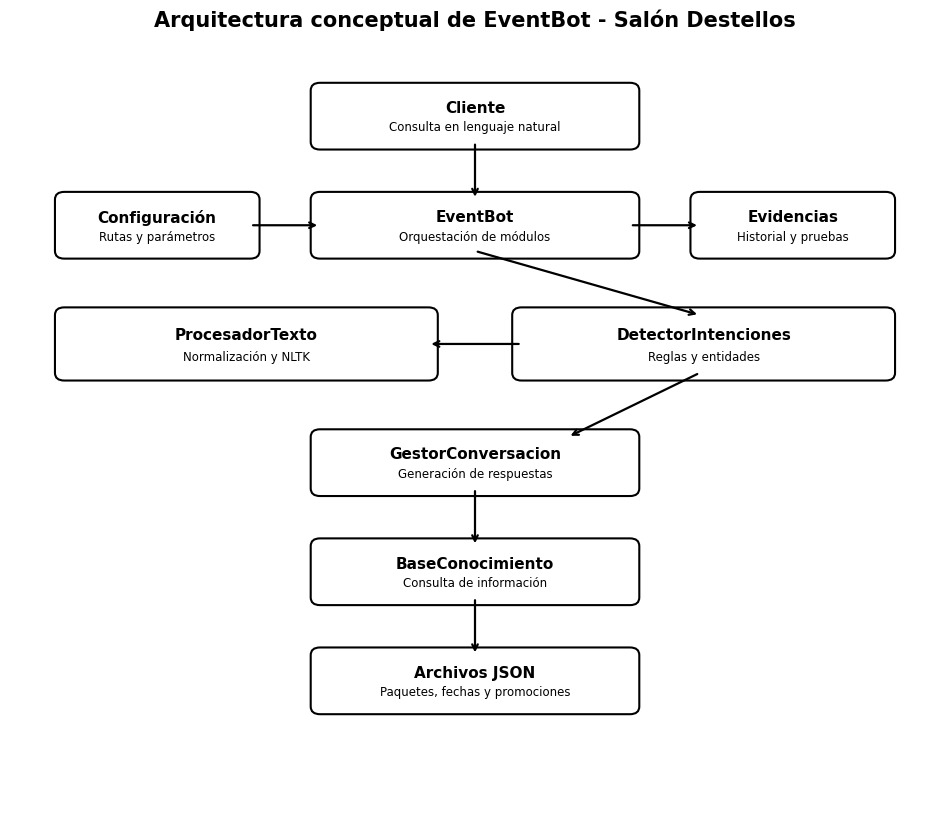

Diagrama guardado en: /content/EventBot/resultados/arquitectura_eventbot.png


In [65]:

# ============================================
# GENERAR DIAGRAMA DE ARQUITECTURA
# ============================================

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from pathlib import Path

fig, ax = plt.subplots(figsize=(12, 10))

ax.set_xlim(0, 12)
ax.set_ylim(0, 12)
ax.axis("off")

def dibujar_modulo(x, y, ancho, alto, titulo, descripcion):
    rect = FancyBboxPatch(
        (x, y),
        ancho,
        alto,
        boxstyle="round,pad=0.12",
        linewidth=1.5,
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(rect)

    ax.text(
        x + ancho / 2,
        y + alto * 0.66,
        titulo,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

    ax.text(
        x + ancho / 2,
        y + alto * 0.28,
        descripcion,
        ha="center",
        va="center",
        fontsize=8.5
    )

def flecha(x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.6
        )
    )

dibujar_modulo(
    4, 10.6, 4, 0.8,
    "Cliente", "Consulta en lenguaje natural"
)

dibujar_modulo(
    4, 8.9, 4, 0.8,
    "EventBot", "Orquestación de módulos"
)

dibujar_modulo(
    0.7, 7.0, 4.7, 0.9,
    "ProcesadorTexto", "Normalización y NLTK"
)

dibujar_modulo(
    6.6, 7.0, 4.7, 0.9,
    "DetectorIntenciones", "Reglas y entidades"
)

dibujar_modulo(
    4, 5.2, 4, 0.8,
    "GestorConversacion", "Generación de respuestas"
)

dibujar_modulo(
    4, 3.5, 4, 0.8,
    "BaseConocimiento", "Consulta de información"
)

dibujar_modulo(
    4, 1.8, 4, 0.8,
    "Archivos JSON", "Paquetes, fechas y promociones"
)

dibujar_modulo(
    0.7, 8.9, 2.4, 0.8,
    "Configuración", "Rutas y parámetros"
)

dibujar_modulo(
    8.9, 8.9, 2.4, 0.8,
    "Evidencias", "Historial y pruebas"
)

flecha(6, 10.6, 6, 9.7)
flecha(6, 8.9, 8.9, 7.9)
flecha(6.6, 7.45, 5.4, 7.45)
flecha(8.9, 7.0, 7.2, 6.0)
flecha(6, 5.2, 6, 4.3)
flecha(6, 3.5, 6, 2.6)

# Conexiones auxiliares
flecha(3.1, 9.3, 4, 9.3)
flecha(8, 9.3, 8.9, 9.3)

ax.set_title(
    "Arquitectura conceptual de EventBot - Salón Destellos",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ruta_resultados = Path("/content/EventBot/resultados")
ruta_resultados.mkdir(parents=True, exist_ok=True)

ruta_diagrama = (
    ruta_resultados / "arquitectura_eventbot.png"
)

plt.savefig(
    ruta_diagrama,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Diagrama guardado en:", ruta_diagrama)


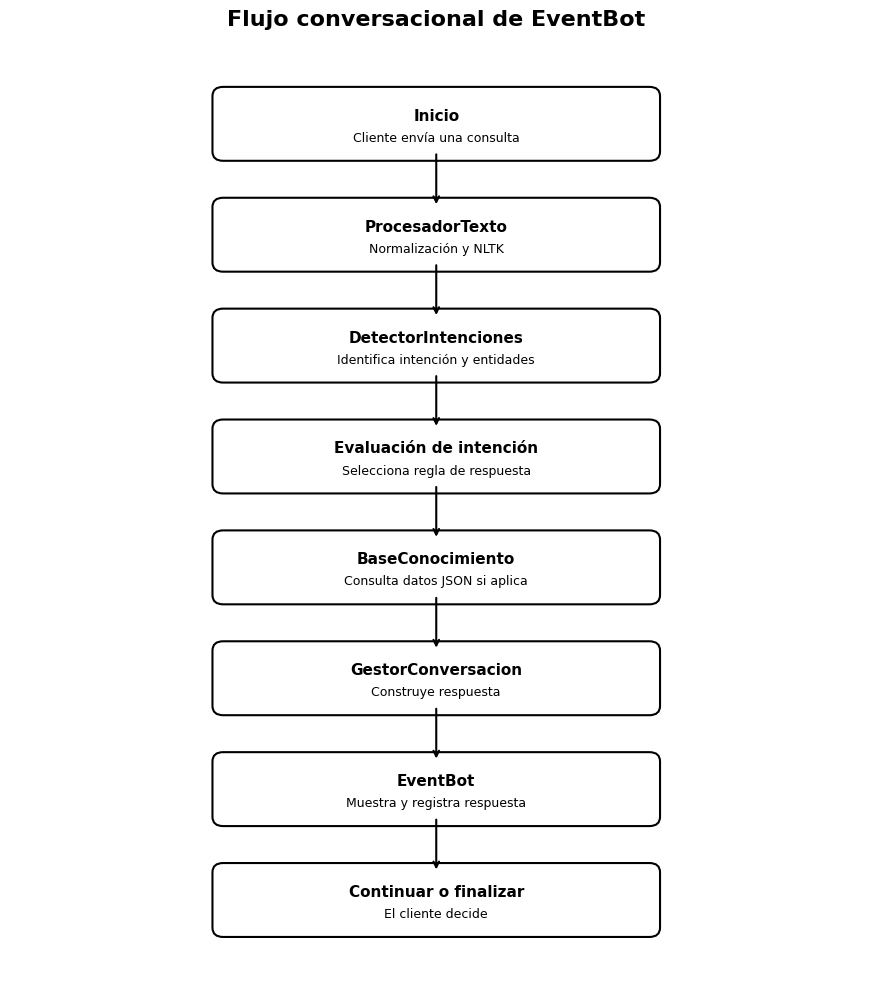

Diagrama guardado en: /content/EventBot/resultados/flujo_conversacional_eventbot.png


In [66]:

# ============================================
# EVENTBOT - DIAGRAMA DE FLUJO CONVERSACIONAL
# ============================================

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from pathlib import Path

fig, ax = plt.subplots(figsize=(11, 12))

ax.set_xlim(0, 12)
ax.set_ylim(0, 15)
ax.axis("off")

def bloque(x, y, ancho, alto, titulo, descripcion=""):
    rect = FancyBboxPatch(
        (x, y), ancho, alto,
        boxstyle="round,pad=0.15",
        linewidth=1.5,
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(rect)

    ax.text(
        x + ancho / 2,
        y + alto * 0.65,
        titulo,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

    if descripcion:
        ax.text(
            x + ancho / 2,
            y + alto * 0.25,
            descripcion,
            ha="center",
            va="center",
            fontsize=9
        )

def conectar(x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.5
        )
    )

bloque(3, 13.4, 6, 0.9, "Inicio", "Cliente envía una consulta")
bloque(3, 11.6, 6, 0.9, "ProcesadorTexto", "Normalización y NLTK")
bloque(3, 9.8, 6, 0.9, "DetectorIntenciones", "Identifica intención y entidades")
bloque(3, 8.0, 6, 0.9, "Evaluación de intención", "Selecciona regla de respuesta")
bloque(3, 6.2, 6, 0.9, "BaseConocimiento", "Consulta datos JSON si aplica")
bloque(3, 4.4, 6, 0.9, "GestorConversacion", "Construye respuesta")
bloque(3, 2.6, 6, 0.9, "EventBot", "Muestra y registra respuesta")
bloque(3, 0.8, 6, 0.9, "Continuar o finalizar", "El cliente decide")

for y1, y2 in [
    (13.4, 12.5),
    (11.6, 10.7),
    (9.8, 8.9),
    (8.0, 7.1),
    (6.2, 5.3),
    (4.4, 3.5),
    (2.6, 1.7)
]:
    conectar(6, y1, 6, y2)

ax.set_title(
    "Flujo conversacional de EventBot",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ruta_resultados = Path("/content/EventBot/resultados")
ruta_resultados.mkdir(parents=True, exist_ok=True)

ruta_flujo = ruta_resultados / "flujo_conversacional_eventbot.png"

plt.savefig(
    ruta_flujo,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Diagrama guardado en:", ruta_flujo)


In [67]:

# ============================================
# EVENTBOT - DOCUMENTACIÓN DE INTENCIONES
# ============================================

import pandas as pd
from pathlib import Path

catalogo_intenciones = [
    {
        "intencion": "saludo",
        "ejemplo": "Hola, buenos días",
        "entidades": "Ninguna",
        "accion": "Presentar al asistente"
    },
    {
        "intencion": "costos",
        "ejemplo": "¿Cuánto cuesta el paquete Premium?",
        "entidades": "Paquete, invitados",
        "accion": "Consultar precios o recomendar paquete"
    },
    {
        "intencion": "paquetes",
        "ejemplo": "¿Qué incluye el paquete Diamante?",
        "entidades": "Paquete, invitados",
        "accion": "Mostrar paquetes y servicios"
    },
    {
        "intencion": "disponibilidad",
        "ejemplo": "¿Está disponible el 15 de noviembre de 2026?",
        "entidades": "Fecha",
        "accion": "Consultar calendario simulado"
    },
    {
        "intencion": "promociones",
        "ejemplo": "¿Qué promociones manejan?",
        "entidades": "Ninguna",
        "accion": "Consultar promociones vigentes"
    },
    {
        "intencion": "amenidades",
        "ejemplo": "¿Tienen estacionamiento?",
        "entidades": "Ninguna",
        "accion": "Informar amenidades del salón"
    },
    {
        "intencion": "capacidad",
        "ejemplo": "¿Cuál es la capacidad máxima?",
        "entidades": "Ninguna",
        "accion": "Informar capacidad del salón"
    },
    {
        "intencion": "ubicacion",
        "ejemplo": "¿Dónde están ubicados?",
        "entidades": "Ninguna",
        "accion": "Informar ubicación simulada"
    },
    {
        "intencion": "horarios",
        "ejemplo": "¿Cuál es su horario?",
        "entidades": "Ninguna",
        "accion": "Informar horarios de atención"
    },
    {
        "intencion": "reservacion",
        "ejemplo": "¿Cómo puedo reservar?",
        "entidades": "Ninguna",
        "accion": "Explicar proceso de reservación"
    },
    {
        "intencion": "tipos_eventos",
        "ejemplo": "¿Organizan bodas?",
        "entidades": "Ninguna",
        "accion": "Informar tipos de eventos"
    },
    {
        "intencion": "agradecimiento",
        "ejemplo": "Muchas gracias",
        "entidades": "Ninguna",
        "accion": "Responder cordialmente"
    },
    {
        "intencion": "despedida",
        "ejemplo": "Adiós",
        "entidades": "Ninguna",
        "accion": "Despedir al cliente"
    },
    {
        "intencion": "desconocida",
        "ejemplo": "¿De qué color es el cielo?",
        "entidades": "Ninguna",
        "accion": "Solicitar una consulta relacionada"
    }
]

df_intenciones = pd.DataFrame(catalogo_intenciones)

display(df_intenciones)

ruta_catalogo = (
    Path("/content/EventBot/resultados")
    / "catalogo_intenciones_eventbot.csv"
)

df_intenciones.to_csv(
    ruta_catalogo,
    index=False,
    encoding="utf-8-sig"
)

print("Catálogo guardado:", ruta_catalogo)


,intencion,ejemplo,entidades,accion
0,saludo,"Hola, buenos días",Ninguna,Presentar al asistente
1,costos,¿Cuánto cuesta el paquete Premium?,"Paquete, invitados",Consultar precios o recomendar paquete
2,paquetes,¿Qué incluye el paquete Diamante?,"Paquete, invitados",Mostrar paquetes y servicios
3,disponibilidad,¿Está disponible el 15 de noviembre de 2026?,Fecha,Consultar calendario simulado
4,promociones,¿Qué promociones manejan?,Ninguna,Consultar promociones vigentes
5,amenidades,¿Tienen estacionamiento?,Ninguna,Informar amenidades del salón
6,capacidad,¿Cuál es la capacidad máxima?,Ninguna,Informar capacidad del salón
7,ubicacion,¿Dónde están ubicados?,Ninguna,Informar ubicación simulada
8,horarios,¿Cuál es su horario?,Ninguna,Informar horarios de atención
9,reservacion,¿Cómo puedo reservar?,Ninguna,Explicar proceso de reservación


Catálogo guardado: /content/EventBot/resultados/catalogo_intenciones_eventbot.csv



## Entidades reconocidas por EventBot

El chatbot extrae tres tipos principales de entidades:

### Paquete
Identifica los paquetes Esencial, Clásico,
Premium y Diamante.

Ejemplo:
"¿Cuánto cuesta el paquete Premium?"

Entidad:
paquete = "Premium"

### Invitados
Identifica cantidades numéricas de asistentes.

Ejemplo:
"¿Cuánto cuesta para 120 personas?"

Entidad:
invitados = 120

### Fecha
Reconoce fechas en formatos predefinidos.

Ejemplo:
"¿Está disponible el 15 de noviembre de 2026?"

Entidad:
fecha = "2026-11-15"

## Consideraciones

Las entidades se extraen mediante expresiones regulares
y reglas predefinidas.

El sistema no utiliza un modelo de reconocimiento
de entidades nombradas entrenado mediante
aprendizaje automático.



## Limitaciones y oportunidades de mejora

### 1. Procesamiento de lenguaje natural

EventBot utiliza NLTK para tokenizar consultas
y reglas predefinidas para detectar intenciones.

Como mejora futura, podría incorporarse un modelo
de clasificación de texto entrenado con ejemplos
de consultas de clientes.

Esto permitiría reconocer diferentes maneras
de expresar una misma necesidad.

### 2. Memoria conversacional

Actualmente, EventBot registra el historial,
pero no utiliza las interacciones anteriores
para interpretar preguntas de seguimiento.

Se propone implementar un gestor de contexto
que conserve entidades relevantes, como el paquete,
la fecha y la cantidad de invitados.

### 3. Clasificación de imágenes

En una versión futura, EventBot podría permitir
que los clientes compartan fotografías de
decoraciones o montajes de eventos.

Mediante un modelo de clasificación de imágenes,
el sistema podría identificar estilos como
clásico, moderno, elegante o temático.

La clasificación serviría para sugerir opciones
de decoración y paquetes relacionados.

### 4. Integración web

Actualmente, los precios, promociones y fechas
se consultan desde archivos JSON simulados.

Una futura integración mediante API permitiría
consultar disponibilidad actualizada, administrar
reservaciones y sincronizar información comercial.

### 5. Evaluación con usuarios reales

Las pruebas actuales incluyeron 50 consultas
distribuidas en 10 conversaciones.

Se obtuvo una exactitud de clasificación del 100%
en este conjunto de pruebas.

Sin embargo, se requiere evaluar el sistema
con consultas nuevas y formulaciones no previstas
para determinar su capacidad de generalización.


In [68]:

# ============================================
# VALIDAR DOCUMENTACIÓN TÉCNICA
# ============================================

from pathlib import Path

ruta_resultados = Path("/content/EventBot/resultados")

archivos_requeridos = [
    "arquitectura_eventbot.png",
    "flujo_conversacional_eventbot.png",
    "catalogo_intenciones_eventbot.csv"
]

for archivo in archivos_requeridos:

    ruta = ruta_resultados / archivo

    if ruta.exists():
        print("[OK]", archivo)
    else:
        print("[PENDIENTE]", archivo)

assert all(
    (ruta_resultados / archivo).exists()
    for archivo in archivos_requeridos
)

print("\nDocumentación técnica validada correctamente.")


[OK] arquitectura_eventbot.png
[OK] flujo_conversacional_eventbot.png
[OK] catalogo_intenciones_eventbot.csv

Documentación técnica validada correctamente.


In [69]:

%%writefile /content/EventBot/README.md
# EventBot – Salón Destellos

## Descripción

EventBot es un prototipo de chatbot desarrollado en Python
para apoyar la atención y cotización de eventos sociales
del Salón Destellos, un negocio ficticio ubicado en Monterrey,
Nuevo León, México.

El asistente permite consultar paquetes, precios,
disponibilidad de fechas, promociones, capacidad,
amenidades y procedimientos de reservación.

## Objetivo

Desarrollar un asistente conversacional modular basado
en reglas que permita automatizar respuestas a consultas
frecuentes de clientes interesados en eventos sociales.

## Tecnologías utilizadas

- Python 3.10 o superior
- NLTK
- Google Colab
- JSON
- Pandas y Matplotlib para evaluación y visualización
- Programación orientada a objetos

## Arquitectura

El proyecto incluye los siguientes módulos:

- `configuracion.py`: configuración y rutas.
- `base_conocimiento.py`: acceso a datos JSON.
- `procesador_texto.py`: normalización y tokenización.
- `detector_intenciones.py`: identificación de intenciones.
- `gestor_conversacion.py`: generación de respuestas.
- `eventbot.py`: integración y ejecución del chatbot.

## Funcionalidades

1. Consultar paquetes y precios.
2. Recomendar paquetes según invitados.
3. Consultar disponibilidad simulada.
4. Informar promociones.
5. Consultar capacidad y amenidades.
6. Informar ubicación y horarios.
7. Explicar el procedimiento de reservación.
8. Registrar conversaciones.

## Instalación

Instalar las dependencias:

```bash
pip install -r requirements.txt
```

## Ejecución en Google Colab

Abrir el notebook `notebooks/EventBot_Colab.ipynb`
y ejecutar sus celdas en orden.

Para iniciar el chatbot desde Python:

```python
from src.eventbot import EventBot

bot = EventBot("/content/EventBot")
bot.conversar()
```

## Pruebas funcionales

Se realizaron 10 conversaciones de prueba con
50 consultas en total.

Resultados:
- Consultas evaluadas: 50.
- Intenciones correctas: 50.
- Exactitud de clasificación: 100%.

Este resultado corresponde únicamente al conjunto
de pruebas definido para el prototipo.

## Limitaciones

- El chatbot utiliza reglas predefinidas.
- No interpreta el contexto de mensajes anteriores.
- Los datos comerciales son simulados.
- No realiza reservaciones ni pagos reales.
- No procesa imágenes.
- No cuenta con integración web en tiempo real.

## Mejoras futuras

- Clasificación de intenciones mediante modelos NLP.
- Memoria conversacional.
- Integración con calendarios y APIs.
- Clasificación de imágenes de decoración.
- Interfaz web para clientes.

## Consideraciones

Este proyecto tiene fines exclusivamente académicos.
Salón Destellos y sus datos son ficticios.
```


Writing /content/EventBot/README.md


In [70]:

%%writefile /content/EventBot/requirements.txt
nltk>=3.8,<4
pandas>=2.0,<3
matplotlib>=3.7,<4


Writing /content/EventBot/requirements.txt


In [71]:

%%writefile /content/EventBot/main.py

from pathlib import Path

from src.eventbot import EventBot


def main():
    ruta_proyecto = Path(__file__).resolve().parent

    bot = EventBot(ruta_proyecto)
    bot.conversar()


if __name__ == "__main__":
    main()


Writing /content/EventBot/main.py


In [76]:

# ============================================
# PRUEBA FINAL DE EJECUCIÓN
# ============================================

import sys

if "/content/EventBot" not in sys.path:
    sys.path.insert(0, "/content/EventBot")

from src.eventbot import EventBot

bot = EventBot("/content/EventBot")

preguntas = [
    "Hola",
    "¿Qué paquetes ofrecen?",
    "¿Cuánto cuesta el paquete Premium?",
    "¿Está disponible el 15 de noviembre de 2026?",
    "¿Cómo puedo reservar?"
]

for pregunta in preguntas:
    print("\nCliente:", pregunta)
    print("EventBot:", bot.responder(pregunta))

assert len(bot.obtener_historial()) == 5

print("\nPrueba final completada.")



Cliente: Hola
EventBot: ¡Hola! Bienvenido a Salón Destellos. Soy EventBot, tu asistente virtual. Puedo ayudarte a consultar paquetes, precios, disponibilidad, promociones y reservaciones. ¿En qué puedo ayudarte?

Cliente: ¿Qué paquetes ofrecen?
EventBot: En Salón Destellos ofrecemos cuatro paquetes: Esencial, Clásico, Premium, Diamante. ¿De cuál te gustaría conocer los servicios?

Cliente: ¿Cuánto cuesta el paquete Premium?
EventBot: El paquete Premium tiene un costo de $48,000.00 MXN. Tiene capacidad para hasta 150 invitados e incluye: Renta del salón, Mesas y sillas, Mantelería, Aire acondicionado, Equipo de sonido, Iluminación ambiental, Pista de baile, Decoración básica.

Cliente: ¿Está disponible el 15 de noviembre de 2026?
EventBot: Según nuestro calendario de demostración, el 2026-11-15 está disponible. Para reservarlo es necesario confirmar la fecha con un asesor.

Cliente: ¿Cómo puedo reservar?
EventBot: Para reservar en Salón Destellos: El cliente debe consultar la disponibi